# MOSAIC - Molecular Occupancy and Structural Analysis of Interacting Contacts

**Objetivo.** Cuantificar la persistencia y diversidad de contactos residuo–residuo (VDW, puentes de hidrógeno y contactos iónicos) a partir de matrices `.cm` de RING, con dos módulos independientes:

1. **Análisis principal filtrado:** respeta el modo y las cadenas seleccionadas por el usuario.
2. **Análisis obligatorio del blanco:** analiza siempre la cadena target frente a las cadenas identificadas como péptidos (o, si se deja vacío, frente a todas las demás cadenas).

> La ocupancia describe persistencia temporal del contacto en la trayectoria. No equivale por sí sola a afinidad de unión, energía libre ni importancia funcional.

**Verificación del conjunto de archivos cargado en esta conversación:** el README indica que A corresponde a la proteína y B, C y D a péptidos. La comparación de etiquetas del primer modelo del PDB con las matrices `.cm` detecta el residuo **A:112:_:HSD** en el PDB, pero no en las etiquetas de VDW, HBOND ni IONIC. El notebook debe mostrarlo como advertencia y excluirlo de métricas de contacto, sin desplazar índices ni inventar contactos. La detección se vuelve a ejecutar con los archivos que cargue el usuario; no está fijada a ese residuo.


## 0. Preparación e importación

Esta celda carga las librerías para leer las matrices, procesar los datos y generar tablas y figuras científicas. El notebook está pensado para ejecutarse en **Google Colab**.

In [1]:
import re
import json
import shutil
import warnings
from pathlib import Path
from collections import OrderedDict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

sns.set_theme(style="whitegrid", context="notebook", palette="viridis")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("✓ Librerías cargadas.")
print("Entorno:", "Google Colab" if EN_COLAB else "Jupyter local")

✓ Librerías cargadas.
Entorno: Google Colab


## 1. Carga, validación y vista previa de archivos

Carga el PDB y los tres archivos de matrices generados por RING: `.cm_VDW`, `.cm_HBOND` y `.cm_IONIC`. La validación comprueba que estén presentes, que no haya archivos duplicados y que cada archivo tenga contenido legible. También muestra una vista previa para detectar errores de formato antes del procesamiento.

**Importancia:** evita iniciar el análisis con archivos incompletos, intercambiados o pertenecientes a simulaciones diferentes.

In [2]:
# En Colab se pueden seleccionar los cuatro archivos en una sola operación.
if EN_COLAB:
    print("Seleccioná el PDB y los tres archivos .cm (VDW, HBOND, IONIC).")
    uploaded = files.upload()
    archivos_cargados = {nombre: Path(nombre) for nombre in uploaded}
else:
    carpeta = Path(".")
    archivos_cargados = {p.name: p for p in carpeta.iterdir() if p.is_file()}

def localizar_archivo(sufijo, extensiones=None):
    candidatos = [
        p for nombre, p in archivos_cargados.items()
        if nombre.lower().endswith(sufijo.lower())
    ]
    if len(candidatos) != 1:
        raise FileNotFoundError(
            f"Se esperaba exactamente un archivo terminado en '{sufijo}', "
            f"pero se encontraron {len(candidatos)}: {[p.name for p in candidatos]}"
        )
    return candidatos[0]

# El PDB puede tener cualquier nombre, pero debe ser único.
pdb_candidatos = [p for nombre, p in archivos_cargados.items() if p.suffix.lower() == ".pdb"]
if len(pdb_candidatos) != 1:
    raise FileNotFoundError(
        f"Se esperaba exactamente un archivo .pdb y se encontraron {len(pdb_candidatos)}."
    )

PDB_PATH = pdb_candidatos[0]
ARCHIVOS = {
    "VDW": localizar_archivo(".cm_VDW"),
    "HBOND": localizar_archivo(".cm_HBOND"),
    "SALTBRIDGE": localizar_archivo(".cm_IONIC")
}

print("\nRESUMEN DE ARCHIVOS")
for tipo, ruta in [("PDB", PDB_PATH), *ARCHIVOS.items()]:
    if not ruta.exists() or ruta.stat().st_size == 0:
        raise FileNotFoundError(f"El archivo {ruta.name} no existe o está vacío.")
    print(f"✓ {tipo:12s} | {ruta.name} | {ruta.stat().st_size:,} bytes")

print("\nVISTA PREVIA — primeras 5 líneas de cada archivo")
for tipo, ruta in [("PDB", PDB_PATH), *ARCHIVOS.items()]:
    print(f"\n--- {tipo}: {ruta.name} ---")
    with open(ruta, "r", errors="replace") as f:
        for i, linea in enumerate(f):
            if i == 5:
                break
            print(linea.rstrip()[:220])

Seleccioná el PDB y los tres archivos .cm (VDW, HBOND, IONIC).


Saving prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_HBOND to prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_HBOND
Saving prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_IONIC to prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_IONIC
Saving prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_VDW to prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_VDW
Saving prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.pdb to prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.pdb

RESUMEN DE ARCHIVOS
✓ PDB          | prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.pdb | 109,224,843 bytes
✓ VDW          | prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_VDW | 28,843,680 bytes
✓ HBOND        | prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_HBOND | 28,843,680 bytes
✓ SALTBRIDGE   | prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.cm_IONIC | 28,843,680 bytes

VISTA PREVIA — primeras 5 líneas de cada archivo

--- PDB: prot_PROC_COMP_CLUS_RENUMERADO_1x3_DUP.pdb ---
REMARK    GENERATED BY TRJCONV
TITLE     Title t=   0.00000 step= 0
REMARK    THIS IS A SIMULATION BOX
CRYST1   93.745   93.745   93

## 2. Configuración general

El `cutoff` define cuándo un tipo de interacción se considera presente para el cálculo de diversidad. Por defecto es **0,05 (5 % de los frames)**. También se configuran la cantidad de candidatos que se muestran y la resolución de las figuras.

**Importancia:** mantener los parámetros centralizados permite reproducir y comparar análisis.

In [3]:
CONFIG = {
    "min_occupancy_cutoff": 0.05,
    "top_n": 20,
    "max_pairs_plot": 40,
    "figure_dpi": 300,
    "output_dir": "resultados_ring"
}

CUTOFF = float(CONFIG["min_occupancy_cutoff"])
if not 0 <= CUTOFF <= 1:
    raise ValueError("El cutoff debe estar entre 0 y 1.")

OUTPUT_DIR = Path(CONFIG["output_dir"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TIPOS = ["VDW", "HBOND", "SALTBRIDGE"]
COL_OCC = {
    "VDW": "vdw_occupancy",
    "HBOND": "hbond_occupancy",
    "SALTBRIDGE": "saltbridge_occupancy"
}
SIGNIFICADO_INTERACCIONES = {
    "VDW": "Van der Waals: contactos de proximidad y complementariedad de superficies.",
    "HBOND": "Puentes de hidrógeno: interacciones entre grupos donadores y aceptores.",
    "SALTBRIDGE": "Interacciones iónicas/puentes salinos: contactos entre grupos con cargas opuestas."
}

print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

{
  "min_occupancy_cutoff": 0.05,
  "top_n": 20,
  "max_pairs_plot": 40,
  "figure_dpi": 300,
  "output_dir": "resultados_ring"
}


## 3. Lectura y validación de las matrices de contacto

Cada archivo se interpreta como una secuencia de matrices cuadradas, una por frame. Los valores mayores que cero se convierten en presencia de contacto (`1`). Se verifica que todos los frames tengan el mismo número de residuos, que las matrices sean cuadradas y que las etiquetas de residuos no cambien entre frames.

**Importancia:** garantiza que las tres categorías describan la misma trayectoria y el mismo conjunto ordenado de residuos.

In [4]:
def leer_matriz_contactos(ruta, tipo):
    with open(ruta, "r", errors="replace") as f:
        lineas = [linea.strip() for linea in f if linea.strip()]

    if not lineas:
        raise ValueError(f"{ruta.name} no contiene datos.")

    registros_por_frame = OrderedDict()
    for numero_linea, linea in enumerate(lineas, start=1):
        partes = linea.split()
        if len(partes) < 3:
            raise ValueError(f"Formato inválido en {ruta.name}, línea {numero_linea}.")
        try:
            frame_id = int(float(partes[0]))
            valores = np.asarray([float(x) for x in partes[2:]], dtype=float)
        except ValueError as exc:
            raise ValueError(f"No se pudieron interpretar números en línea {numero_linea}: {linea[:100]}") from exc

        etiqueta = partes[1]
        registros_por_frame.setdefault(frame_id, []).append((etiqueta, valores))

    frames = []
    etiquetas_referencia = None
    for frame_id, filas in registros_por_frame.items():
        etiquetas = [x[0] for x in filas]
        if etiquetas_referencia is None:
            etiquetas_referencia = etiquetas
        elif etiquetas != etiquetas_referencia:
            raise ValueError(f"Las etiquetas/orden de residuos cambian en frame {frame_id} de {ruta.name}.")

        n = len(filas)
        if any(len(valores) != n for _, valores in filas):
            dimensiones = [len(v) for _, v in filas]
            raise ValueError(
                f"Matriz no cuadrada en {ruta.name}, frame {frame_id}: "
                f"{n} filas y longitudes {sorted(set(dimensiones))}."
            )

        matriz = np.vstack([v for _, v in filas])
        frames.append((matriz > 0).astype(np.uint8))

    print(f"✓ {tipo}: {len(frames)} frames | {len(etiquetas_referencia)} residuos | matriz {len(etiquetas_referencia)}×{len(etiquetas_referencia)}")
    return frames, etiquetas_referencia, list(registros_por_frame.keys())

datos = {}
for tipo, ruta in ARCHIVOS.items():
    datos[tipo] = leer_matriz_contactos(ruta, tipo)

frames_vdw, residues, ids_frames = datos["VDW"]
frames_hbond, residues_hbond, ids_hbond = datos["HBOND"]
frames_saltbridge, residues_saltbridge, ids_saltbridge = datos["SALTBRIDGE"]

if not (ids_frames == ids_hbond == ids_saltbridge):
    raise ValueError("⚠️ ALERTA: los archivos no contienen los mismos identificadores/orden de frames.")
if not (residues == residues_hbond == residues_saltbridge):
    raise ValueError("⚠️ ALERTA: las etiquetas u orden de residuos difieren entre archivos.")
if len(frames_vdw) == 0:
    raise ValueError("No hay frames para analizar.")

N_FRAMES = len(frames_vdw)

# Verificación metodológica de las matrices: simetría, diagonal y dimensiones.
# Los valores pueden ser 0, 1, 2, 3, etc.; para ocupancia se interpretan como
# presencia/ausencia (0 = sin contacto; >0 = contacto).
for tipo, (matrices, etiquetas, ids) in datos.items():
    for indice, matriz in enumerate(matrices):
        if matriz.shape != (len(etiquetas), len(etiquetas)):
            raise ValueError(
                f"⚠️ ALERTA: dimensión inesperada en {tipo}, frame {ids[indice]}."
            )
        if not np.array_equal(matriz, matriz.T):
            raise ValueError(
                f"⚠️ ALERTA: la matriz {tipo}, frame {ids[indice]} no es simétrica."
            )
        if np.any(np.diag(matriz) != 0):
            raise ValueError(
                f"⚠️ ALERTA: hay contactos en la diagonal de {tipo}, frame {ids[indice]}."
            )

print(
    f"\\n✓ Validación cruzada completa: {N_FRAMES} frames y "
    f"{len(residues)} residuos."
)
print("✓ Las matrices son cuadradas, simétricas y tienen diagonal nula.")
print("ℹ️ Los valores positivos se interpretan como presencia de contacto; "
      "la magnitud (1, 2, 3...) no se suma como ocupancia.")

✓ VDW: 501 frames | 166 residuos | matriz 166×166
✓ HBOND: 501 frames | 166 residuos | matriz 166×166
✓ SALTBRIDGE: 501 frames | 166 residuos | matriz 166×166
\n✓ Validación cruzada completa: 501 frames y 166 residuos.
✓ Las matrices son cuadradas, simétricas y tienen diagonal nula.
ℹ️ Los valores positivos se interpretan como presencia de contacto; la magnitud (1, 2, 3...) no se suma como ocupancia.


## 4. Detección de cadenas en el PDB y correspondencia exacta PDB–RING

Se identifican las cadenas y los residuos del **primer modelo** del PDB y se comparan con las etiquetas presentes en cada archivo `.cm`. La correspondencia se realiza por cadena, número, código de inserción y nombre del residuo; no se infiere por posición ni se desplazan índices para compensar ausencias.

El control distingue dos situaciones:
- **Residuo del PDB ausente en RING:** se informa como advertencia explícita, indicando cadena, número y nombre. Ese residuo no puede participar en métricas basadas en las matrices porque no tiene fila/columna en ellas.
- **Etiqueta RING sin correspondencia en el PDB:** también se informa y no se asigna silenciosamente.

Además, se verifica que los tres archivos `.cm` tengan exactamente las mismas etiquetas y orden, y se presenta el número de residuos por cadena.

**Importancia:** conserva la verificación metodológica por cadenas y evita asociar contactos a residuos incorrectos cuando RING omite un residuo.

In [5]:

# Leer los residuos del primer modelo del PDB para evitar duplicar los mismos
# residuos a lo largo de los modelos de la trayectoria.
residuos_pdb_por_cadena = OrderedDict()
modelo_encontrado = False

with open(PDB_PATH, "r", errors="replace") as f:
    for linea in f:
        if linea.startswith("MODEL"):
            if modelo_encontrado:
                break
            modelo_encontrado = True
            continue
        if linea.startswith("ENDMDL") and modelo_encontrado:
            break
        if linea.startswith(("ATOM  ", "HETATM")) and len(linea) >= 27:
            cadena = linea[21].strip() or "_"
            nombre_res = linea[17:20].strip().upper()
            id_res = linea[22:27].strip()
            residuos_pdb_por_cadena.setdefault(cadena, [])
            item = (id_res, nombre_res)
            if item not in residuos_pdb_por_cadena[cadena]:
                residuos_pdb_por_cadena[cadena].append(item)

if not residuos_pdb_por_cadena:
    raise ValueError("No se detectaron residuos ATOM/HETATM en el primer modelo del PDB.")

def clave_residuo_pdb(cadena, id_res, nombre_res):
    id_limpio = str(id_res).strip()
    insercion = id_limpio[-1] if len(id_limpio) > 1 and id_limpio[-1].isalpha() else ""
    numero = id_limpio[:-1].strip() if insercion else id_limpio
    return (str(cadena).strip() or "_", numero, insercion, str(nombre_res).strip().upper())

indice_pdb = {}
for cadena, lista in residuos_pdb_por_cadena.items():
    for id_res, nombre_res in lista:
        indice_pdb[clave_residuo_pdb(cadena, id_res, nombre_res)] = {
            "chain": cadena,
            "pdb_residue_id": id_res,
            "resname": nombre_res
        }

def parsear_etiqueta_ring(etiqueta):
    partes = str(etiqueta).strip().split(":")
    if len(partes) < 4:
        return None
    insercion = "" if partes[2].strip() in ("", "_", ".") else partes[2].strip()
    return (
        partes[0].strip() or "_",
        partes[1].strip(),
        insercion,
        partes[3].strip().upper()
    )

# Comprobar individualmente que las etiquetas y su orden sean idénticos
# en VDW, HBOND e IONIC.
etiquetas_por_tipo = {
    "VDW": datos["VDW"][1],
    "HBOND": datos["HBOND"][1],
    "SALTBRIDGE": datos["SALTBRIDGE"][1]
}
referencia_etiquetas = etiquetas_por_tipo["VDW"]
for tipo, etiquetas_tipo in etiquetas_por_tipo.items():
    if etiquetas_tipo != referencia_etiquetas:
        diferencias = sorted(set(referencia_etiquetas).symmetric_difference(set(etiquetas_tipo)))
        raise ValueError(
            f"⚠️ ALERTA METODOLÓGICA: las etiquetas u orden de {tipo} difieren "
            f"de VDW. Diferencias: {diferencias[:20]}"
        )

mapa_residuos = {}
residuos_ring_sin_match = []
for etiqueta in residues:
    clave = parsear_etiqueta_ring(etiqueta)
    info = indice_pdb.get(clave) if clave else None
    if info is None:
        residuos_ring_sin_match.append(str(etiqueta))
    else:
        mapa_residuos[str(etiqueta)] = {**info, "ring_label": str(etiqueta)}

tabla_mapeo = pd.DataFrame(mapa_residuos.values())
cadenas_disponibles = list(residuos_pdb_por_cadena.keys())

# Diferencia PDB menos RING: residuos presentes en la estructura de entrada
# que no cuentan con fila/columna en las matrices de contacto.
etiquetas_pdb = set(indice_pdb)
etiquetas_ring = {
    clave for etiqueta in residues
    if (clave := parsear_etiqueta_ring(etiqueta)) is not None
}
residuos_pdb_sin_ring = sorted(etiquetas_pdb - etiquetas_ring)

residuos_ausentes_ring = pd.DataFrame([
    {
        "cadena": cadena,
        "numero_residuo_PDB": numero,
        "codigo_insercion": insercion or "",
        "nombre_residuo": nombre,
        "etiqueta_completa": f"{cadena}:{numero}:{insercion or '_'}:{nombre}",
        "estado": "Presente en PDB; ausente en las etiquetas de los tres archivos RING"
    }
    for cadena, numero, insercion, nombre in residuos_pdb_sin_ring
])

print("CADENAS DETECTADAS EN EL PDB (primer modelo)")
for cadena, lista in residuos_pdb_por_cadena.items():
    n_ring = sum(1 for etiqueta in residues
                 if (parsear_etiqueta_ring(etiqueta) or (None,))[0] == cadena)
    print(
        f"  Cadena {cadena}: {len(lista)} residuos en PDB | "
        f"{n_ring} residuos representados en RING"
    )

print(
    f"\nEtiquetas RING: {len(residues)} | "
    f"Mapeadas exactamente: {len(mapa_residuos)} | "
    f"Etiquetas RING sin correspondencia: {len(residuos_ring_sin_match)}"
)

if residuos_ring_sin_match:
    print("⚠️ ALERTA: hay etiquetas RING que no se pudieron asociar al PDB.")
    print("Ejemplos:", residuos_ring_sin_match[:10])

if residuos_pdb_sin_ring:
    print("\n" + "!" * 78)
    print("⚠️ ADVERTENCIA METODOLÓGICA: RESIDUO(S) DEL PDB NO RECONOCIDO(S) POR RING")
    print("!" * 78)
    for cadena, numero, insercion, nombre in residuos_pdb_sin_ring:
        etiqueta = f"{cadena}:{numero}:{insercion or '_'}:{nombre}"
        print(
            f"  • {etiqueta} — presente en el PDB, pero ausente en las etiquetas "
            "de VDW, HBOND e IONIC."
        )
    print(
        "Estos residuos no tienen fila/columna en las matrices .cm. Por lo tanto, "
        "no se pueden calcular ni atribuir contactos RING para ellos. "
        "No se reasignarán índices ni se supondrán contactos."
    )
else:
    print("✓ Todos los residuos del primer modelo del PDB están representados en RING.")

if len(mapa_residuos) == 0:
    raise ValueError(
        "No se pudo mapear ninguna etiqueta RING al PDB. "
        "Revisá el formato de etiquetas y el PDB."
    )

# Resumen de residuos por cadena para auditar el alcance de cada filtro.
resumen_cadenas_mapeo = pd.DataFrame([
    {
        "cadena": cadena,
        "significado": "Pendiente de asignación por el usuario",
        "residuos_PDB": len(lista),
        "residuos_RING": sum(
            1 for etiqueta in residues
            if (parsear_etiqueta_ring(etiqueta) or (None,))[0] == cadena
        ),
        "residuos_PDB_ausentes_RING": sum(
            1 for clave in residuos_pdb_sin_ring if clave[0] == cadena
        )
    }
    for cadena, lista in residuos_pdb_por_cadena.items()
])

print("\nVISTA PREVIA DE CORRESPONDENCIAS PDB–RING")
display(tabla_mapeo.head(15))
print("\nAUDITORÍA DE RESIDUOS POR CADENA")
display(resumen_cadenas_mapeo)
if not residuos_ausentes_ring.empty:
    print("\nRESIDUOS PRESENTES EN PDB Y AUSENTES EN RING")
    display(residuos_ausentes_ring)


CADENAS DETECTADAS EN EL PDB (primer modelo)
  Cadena A: 113 residuos en PDB | 112 residuos representados en RING
  Cadena B: 18 residuos en PDB | 18 residuos representados en RING
  Cadena C: 18 residuos en PDB | 18 residuos representados en RING
  Cadena D: 18 residuos en PDB | 18 residuos representados en RING

Etiquetas RING: 166 | Mapeadas exactamente: 166 | Etiquetas RING sin correspondencia: 0

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
⚠️ ADVERTENCIA METODOLÓGICA: RESIDUO(S) DEL PDB NO RECONOCIDO(S) POR RING
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
  • A:112:_:HSD — presente en el PDB, pero ausente en las etiquetas de VDW, HBOND e IONIC.
Estos residuos no tienen fila/columna en las matrices .cm. Por lo tanto, no se pueden calcular ni atribuir contactos RING para ellos. No se reasignarán índices ni se supondrán contactos.

VISTA PREVIA DE CORRESPONDENCIAS PDB–RING


,chain,pdb_residue_id,resname,ring_label
0,A,2,ALA,A:2:_:ALA
1,A,3,LYS,A:3:_:LYS
2,A,4,LEU,A:4:_:LEU
3,A,5,VAL,A:5:_:VAL
4,A,6,ARG,A:6:_:ARG
5,A,7,PRO,A:7:_:PRO
6,A,8,PRO,A:8:_:PRO
7,A,9,VAL,A:9:_:VAL
8,A,10,GLN,A:10:_:GLN
9,A,11,VAL,A:11:_:VAL



AUDITORÍA DE RESIDUOS POR CADENA


,cadena,significado,residuos_PDB,residuos_RING,residuos_PDB_ausentes_RING
0,A,Pendiente de asignación por el usuario,113,112,1
1,B,Pendiente de asignación por el usuario,18,18,0
2,C,Pendiente de asignación por el usuario,18,18,0
3,D,Pendiente de asignación por el usuario,18,18,0



RESIDUOS PRESENTES EN PDB Y AUSENTES EN RING


,cadena,numero_residuo_PDB,codigo_insercion,nombre_residuo,etiqueta_completa,estado
0,A,112,,HSD,A:112:_:HSD,Presente en PDB; ausente en las etiquetas de l...


## 5. Conversión de matrices a contactos por frame

Se transforma cada matriz en registros `frame–pair`, utilizando solamente el triángulo superior para evitar duplicar `A–B` y `B–A`. Se conservan contactos únicos por frame y par.

**Importancia:** esta tabla es la base común para calcular ocupancias específicas e integradas sin duplicaciones.

In [6]:
def matrices_a_contactos(frames, etiquetas):
    registros = []
    for indice_frame, matriz in enumerate(frames, start=1):
        filas, columnas = np.where(np.triu(matriz, k=1) > 0)
        for i, j in zip(filas, columnas):
            registros.append({
                "frame": indice_frame,
                "pair": f"{etiquetas[i]} - {etiquetas[j]}"
            })
    return pd.DataFrame(registros, columns=["frame", "pair"]).drop_duplicates()

TIPO_A_DF = {
    "VDW": matrices_a_contactos(frames_vdw, residues),
    "HBOND": matrices_a_contactos(frames_hbond, residues),
    "SALTBRIDGE": matrices_a_contactos(frames_saltbridge, residues)
}
for tipo, df in TIPO_A_DF.items():
    print(f"{tipo}: {len(df):,} registros frame-par | {df['pair'].nunique() if not df.empty else 0:,} pares únicos")

VDW: 59,728 registros frame-par | 820 pares únicos
HBOND: 59,778 registros frame-par | 501 pares únicos
SALTBRIDGE: 2,572 registros frame-par | 83 pares únicos


## 6. Selección biológica del análisis principal y definición del blanco

Primero se llesolicita al usuario asignar el significado biológico de cada cadena (por ejemplo: proteína blanco, péptido, subunidad). Luego deberá elegir si el análisis principal será **intramolecular** (una cadena consigo misma) o **intermolecular** (contactos entre cadenas distintas), por último deberá indicar las cadenas y definir el blanco.

Para el análisis obligatorio del blanco, también sse da la opción de indicar qué cadenas corresponden a péptidos. Si el usuario deja ese campo vacío, se usarán todas las cadenas distintas del blanco.

**Importancia:** la interpretación o significdo biológico depende de identificar correctamente las cadenas. Las etiquetas repetidas generan una alerta para confirmar que sean intencionales.

In [7]:
descripcion_cadenas = {}
print("ASIGNACIÓN BIOLÓGICA DE CADENAS")
for cadena in cadenas_disponibles:
    descripcion_cadenas[cadena] = input(
        f"Cadena {cadena} — significado biológico: "
    ).strip() or f"Cadena {cadena}"

conteo_desc = Counter(x.strip().casefold() for x in descripcion_cadenas.values())
repetidas = [desc for desc, n in conteo_desc.items() if n > 1]
if repetidas:
    print("⚠️ ALERTA: se detectaron descripciones biológicas repetidas.")
    for desc in repetidas:
        cs = [c for c, d in descripcion_cadenas.items() if d.strip().casefold() == desc]
        print(f"  '{desc}': cadenas {', '.join(cs)}")
    confirmar = input("¿Las etiquetas repetidas son intencionales? (s/n): ").strip().lower()
    if confirmar not in {"s", "si", "sí"}:
        raise ValueError("Corrija las etiquetas biológicas y vuelva a ejecutar esta celda.")
else:
    print("✓ No hay etiquetas repetidas.")

display(pd.DataFrame([
    {"cadena": c, "significado_biologico": descripcion_cadenas[c],
     "residuos_PDB": len(residuos_pdb_por_cadena[c])}
    for c in cadenas_disponibles
]))

modo_analisis = input(
    "\nTipo de análisis principal: INTRAMOLECULAR o INTERMOLECULAR: "
).strip().upper()
if modo_analisis not in {"INTRAMOLECULAR", "INTERMOLECULAR"}:
    raise ValueError("Modo inválido. Seleccione INTRAMOLECULAR o INTERMOLECULAR.")

if modo_analisis == "INTRAMOLECULAR":
    cadena = input(f"¿Qué cadena analizar? {cadenas_disponibles}: ").strip().upper()
    if cadena not in cadenas_disponibles:
        raise ValueError(f"Cadena inválida: {cadena}")
    CADENAS_ANALISIS = [cadena]
    descripcion_analisis = f"Intramolecular — cadena {cadena} ({descripcion_cadenas[cadena]})"
else:
    texto = input("¿Entre qué cadenas? Separalas por coma (ej. A,B): ").strip().upper().replace(" ", "")
    CADENAS_ANALISIS = list(dict.fromkeys(x for x in texto.split(",") if x))
    invalidas = sorted(set(CADENAS_ANALISIS) - set(cadenas_disponibles))
    if len(CADENAS_ANALISIS) < 2 or invalidas:
        raise ValueError(f"Se requieren al menos dos cadenas válidas. Inválidas: {invalidas}")
    descripcion_analisis = "Intermolecular — " + " vs ".join(CADENAS_ANALISIS)

BLANCO_CADENA = input(f"¿Cuál es la cadena blanco/target? {cadenas_disponibles}: ").strip().upper()
if BLANCO_CADENA not in cadenas_disponibles:
    raise ValueError("La cadena indicada como blanco no existe en el PDB.")

texto_peptidos = input(
    "Cadenas que corresponden a péptidos frente al blanco (coma; Enter = todas las demás): "
).strip().upper().replace(" ", "")
if texto_peptidos:
    CADENAS_PEPTIDOS = list(dict.fromkeys(x for x in texto_peptidos.split(",") if x))
    invalidas = sorted(set(CADENAS_PEPTIDOS) - set(cadenas_disponibles))
    if invalidas or BLANCO_CADENA in CADENAS_PEPTIDOS:
        raise ValueError(f"Selección de péptidos inválida. Cadenas inválidas o blanco incluido: {invalidas}")
else:
    CADENAS_PEPTIDOS = [c for c in cadenas_disponibles if c != BLANCO_CADENA]

if not CADENAS_PEPTIDOS:
    raise ValueError("No hay cadenas péptido seleccionadas para el análisis del blanco.")

texto_tipos = input(
    "Tipos para el análisis principal (VDW, HBOND, SALTBRIDGE; Enter = todos): "
).strip().upper()
TIPOS_PRINCIPAL = TIPOS.copy() if not texto_tipos else list(dict.fromkeys(
    x.strip() for x in texto_tipos.split(",") if x.strip()
))
invalidos = sorted(set(TIPOS_PRINCIPAL) - set(TIPOS))
if invalidos or not TIPOS_PRINCIPAL:
    raise ValueError(f"Tipos de interacción inválidos: {invalidos}")

print("\nRESUMEN DE SELECCIÓN")
print("Análisis principal:", descripcion_analisis)
print("Tipos:", TIPOS_PRINCIPAL)
print("Blanco:", BLANCO_CADENA, "—", descripcion_cadenas[BLANCO_CADENA])
print("Cadenas péptido para análisis del blanco:", CADENAS_PEPTIDOS)
print("Cutoff de diversidad:", CUTOFF)
print("✓ El análisis del blanco se ejecutará independientemente del filtro principal.")

ASIGNACIÓN BIOLÓGICA DE CADENAS
Cadena A — significado biológico: OSCP
Cadena B — significado biológico: IF1
Cadena C — significado biológico: IF1
Cadena D — significado biológico: IF1
⚠️ ALERTA: se detectaron descripciones biológicas repetidas.
  'if1': cadenas B, C, D
¿Las etiquetas repetidas son intencionales? (s/n): s


,cadena,significado_biologico,residuos_PDB
0,A,OSCP,113
1,B,IF1,18
2,C,IF1,18
3,D,IF1,18



Tipo de análisis principal: INTRAMOLECULAR o INTERMOLECULAR: INTERMOLECULAR
¿Entre qué cadenas? Separalas por coma (ej. A,B): A,D
¿Cuál es la cadena blanco/target? ['A', 'B', 'C', 'D']: A
Cadenas que corresponden a péptidos frente al blanco (coma; Enter = todas las demás): 
Tipos para el análisis principal (VDW, HBOND, SALTBRIDGE; Enter = todos): 

RESUMEN DE SELECCIÓN
Análisis principal: Intermolecular — A vs D
Tipos: ['VDW', 'HBOND', 'SALTBRIDGE']
Blanco: A — OSCP
Cadenas péptido para análisis del blanco: ['B', 'C', 'D']
Cutoff de diversidad: 0.05
✓ El análisis del blanco se ejecutará independientemente del filtro principal.


## 7. Funciones de filtrado y cálculo de métricas

Las métricas se calculan por par de residuos:

- **Ocupancia específica:** frames con ese tipo de interacción / total de frames.
- **Ocupancia total integrada:** frames en los que aparece al menos uno de los tipos seleccionados / total de frames. Se usa una unión lógica por `frame–pair`, por lo que un frame con dos o tres tipos simultáneos cuenta una sola vez.
- **Diversidad:** cantidad de tipos cuya ocupancia alcanza o supera el `cutoff`.
- **Tipo predominante:** tipo con mayor ocupancia específica.

**Importancia:** la ocupancia integrada evita sobreestimar la persistencia por sumar categorías simultáneas; la diversidad distingue contactos sostenidos por un único tipo de aquellos con varios tipos.

In [8]:
def obtener_cadenas_del_par(par):
    partes = [x.strip() for x in str(par).split(" - ", 1)]
    if len(partes) != 2:
        return None, None
    i1, i2 = mapa_residuos.get(partes[0]), mapa_residuos.get(partes[1])
    if not i1 or not i2:
        return None, None
    return i1["chain"], i2["chain"]

def anotar_cadenas(df):
    temp = df.copy()
    if temp.empty:
        temp["chain_1"] = pd.Series(dtype="object")
        temp["chain_2"] = pd.Series(dtype="object")
        return temp
    pares_cadenas = temp["pair"].map(obtener_cadenas_del_par)
    temp["chain_1"] = [x[0] for x in pares_cadenas]
    temp["chain_2"] = [x[1] for x in pares_cadenas]
    return temp

CONTACTOS_ANOTADOS = {tipo: anotar_cadenas(df) for tipo, df in TIPO_A_DF.items()}

def filtrar_contactos(modo, cadenas, tipos):
    salida = {}
    for tipo in tipos:
        temp = CONTACTOS_ANOTADOS[tipo].copy()
        if modo == "INTRAMOLECULAR":
            mask = (temp["chain_1"] == cadenas[0]) & (temp["chain_2"] == cadenas[0])
        else:
            mask = (
                temp["chain_1"].isin(cadenas) &
                temp["chain_2"].isin(cadenas) &
                (temp["chain_1"] != temp["chain_2"])
            )
        salida[tipo] = temp.loc[mask, ["frame", "pair"]].drop_duplicates()
    return salida

def tabla_metricas(contactos_por_tipo, tipos, n_frames, cutoff):
    pares = sorted(set().union(*[
        set(contactos_por_tipo[t]["pair"]) for t in tipos
    ])) if tipos else []

    resultado = pd.DataFrame({"pair": pares})
    for tipo in tipos:
        ocupancia = (
            contactos_por_tipo[tipo].groupby("pair")["frame"].nunique() / n_frames
            if not contactos_por_tipo[tipo].empty else pd.Series(dtype=float)
        )
        resultado = resultado.merge(
            ocupancia.rename(COL_OCC[tipo]), left_on="pair", right_index=True, how="left"
        )

    columnas_occ = [COL_OCC[t] for t in tipos]
    if columnas_occ:
        resultado[columnas_occ] = resultado[columnas_occ].fillna(0.0)

    # Unión lógica de todos los tipos por frame y par: no suma ocupancias.
    if tipos:
        union_frames = pd.concat(
            [contactos_por_tipo[t][["frame", "pair"]] for t in tipos],
            ignore_index=True
        ).drop_duplicates(["frame", "pair"])
    else:
        union_frames = pd.DataFrame(columns=["frame", "pair"])

    occ_total = (
        union_frames.groupby("pair")["frame"].nunique() / n_frames
        if not union_frames.empty else pd.Series(dtype=float)
    )
    resultado = resultado.merge(
        occ_total.rename("occupancy_total"), left_on="pair", right_index=True, how="left"
    )
    resultado["occupancy_total"] = resultado["occupancy_total"].fillna(0.0)

    resultado["diversity"] = (
        sum((resultado[COL_OCC[t]] > cutoff).astype(int) for t in tipos)
        if tipos else 0
    )
    resultado["diversity_normalized"] = (
        resultado["diversity"] / len(tipos) if tipos else 0.0
    )

    def predominante(fila):
        valores = {t: fila[COL_OCC[t]] for t in tipos}
        if not valores or max(valores.values()) <= 0:
            return "NONE"
        maximo = max(valores.values())
        return "/".join(t for t, valor in valores.items() if np.isclose(valor, maximo))

    resultado["main_interaction"] = resultado.apply(predominante, axis=1)
    resultado = resultado.sort_values(
        ["occupancy_total", "diversity"], ascending=[False, False]
    ).reset_index(drop=True)
    return resultado

def top_candidatos(df, n=20):
    return df.sort_values(
        ["occupancy_total", "diversity"], ascending=[False, False]
    ).head(n).reset_index(drop=True)

def imprimir_resumen(df, nombre):
    print(f"\n{nombre}")
    print(f"Pares únicos: {len(df)}")
    if not df.empty:
        print(f"Ocupancia integrada máxima: {df['occupancy_total'].max():.1%}")
        print(f"Diversidad máxima: {df['diversity'].max()}")
        print("Tipo predominante más frecuente:")
        display(df["main_interaction"].value_counts().rename_axis("tipo").to_frame("cantidad"))
    else:
        print("⚠️ No se encontraron contactos para este alcance.")

## 8. Análisis principal filtrado por el usuario

Se aplica primero el filtro intramolecular o intermolecular elegido, junto con los tipos de interacción seleccionados. Se muestra la **tabla completa** y un dataframe independiente con el **Top 20**, ordenado por ocupancia total integrada y, en caso de empate, por diversidad.

**Importancia:** identifica los pares más persistentes dentro de la pregunta biológica definida por el usuario, sin mezclar cadenas fuera del alcance seleccionado.

In [9]:
contactos_principal = filtrar_contactos(modo_analisis, CADENAS_ANALISIS, TIPOS_PRINCIPAL)
df_analisis = tabla_metricas(contactos_principal, TIPOS_PRINCIPAL, N_FRAMES, CUTOFF)
df_principal_top20 = top_candidatos(df_analisis, CONFIG["top_n"])

print("ANÁLISIS PRINCIPAL:", descripcion_analisis)
print("Tipos incluidos:", TIPOS_PRINCIPAL)
imprimir_resumen(df_analisis, "Resumen del análisis principal")

print("\nTABLA COMPLETA DEL ANÁLISIS PRINCIPAL")
display(df_analisis)

print("\nTOP 20 DE CANDIDATOS — ocupancia integrada ↓, diversidad ↓")
display(df_principal_top20)

ANÁLISIS PRINCIPAL: Intermolecular — A vs D
Tipos incluidos: ['VDW', 'HBOND', 'SALTBRIDGE']

Resumen del análisis principal
Pares únicos: 56
Ocupancia integrada máxima: 41.5%
Diversidad máxima: 3
Tipo predominante más frecuente:


,cantidad
tipo,
VDW,37
HBOND,14
HBOND/SALTBRIDGE,3
VDW/HBOND/SALTBRIDGE,1
VDW/HBOND,1



TABLA COMPLETA DEL ANÁLISIS PRINCIPAL


,pair,vdw_occupancy,hbond_occupancy,saltbridge_occupancy,occupancy_total,diversity,diversity_normalized,main_interaction
0,A:47:_:LYS - D:33:_:TYR,0.409182,0.009980,0.000000,0.415170,1,0.333333,VDW
1,A:49:_:PRO - D:32:_:ARG,0.373253,0.000000,0.000000,0.373253,1,0.333333,VDW
2,A:47:_:LYS - D:25:_:ARG,0.131737,0.327345,0.000000,0.347305,2,0.666667,HBOND
3,A:49:_:PRO - D:33:_:TYR,0.325349,0.000000,0.000000,0.325349,1,0.333333,VDW
4,A:57:_:ASN - D:39:_:ARG,0.209581,0.057884,0.000000,0.245509,2,0.666667,VDW
5,A:53:_:ALA - D:36:_:ALA,0.245509,0.000000,0.000000,0.245509,1,0.333333,VDW
6,A:52:_:ALA - D:36:_:ALA,0.237525,0.000000,0.000000,0.237525,1,0.333333,VDW
7,A:59:_:TYR - D:39:_:ARG,0.219561,0.000000,0.000000,0.219561,1,0.333333,VDW
8,A:52:_:ALA - D:33:_:TYR,0.217565,0.000000,0.000000,0.217565,1,0.333333,VDW
9,A:49:_:PRO - D:29:_:GLU,0.189621,0.000000,0.000000,0.189621,1,0.333333,VDW



TOP 20 DE CANDIDATOS — ocupancia integrada ↓, diversidad ↓


,pair,vdw_occupancy,hbond_occupancy,saltbridge_occupancy,occupancy_total,diversity,diversity_normalized,main_interaction
0,A:47:_:LYS - D:33:_:TYR,0.409182,0.009980,0.000000,0.415170,1,0.333333,VDW
1,A:49:_:PRO - D:32:_:ARG,0.373253,0.000000,0.000000,0.373253,1,0.333333,VDW
2,A:47:_:LYS - D:25:_:ARG,0.131737,0.327345,0.000000,0.347305,2,0.666667,HBOND
3,A:49:_:PRO - D:33:_:TYR,0.325349,0.000000,0.000000,0.325349,1,0.333333,VDW
4,A:57:_:ASN - D:39:_:ARG,0.209581,0.057884,0.000000,0.245509,2,0.666667,VDW
5,A:53:_:ALA - D:36:_:ALA,0.245509,0.000000,0.000000,0.245509,1,0.333333,VDW
6,A:52:_:ALA - D:36:_:ALA,0.237525,0.000000,0.000000,0.237525,1,0.333333,VDW
7,A:59:_:TYR - D:39:_:ARG,0.219561,0.000000,0.000000,0.219561,1,0.333333,VDW
8,A:52:_:ALA - D:33:_:TYR,0.217565,0.000000,0.000000,0.217565,1,0.333333,VDW
9,A:49:_:PRO - D:29:_:GLU,0.189621,0.000000,0.000000,0.189621,1,0.333333,VDW


## 9. Gráfico científico: ocupancia total integrada vs. diversidad

Cada barra representa un par de residuos; su altura corresponde a la ocupancia total integrada y el color codifica el índice de diversidad. Se grafican los mejores candidatos para facilitar la lectura. El color se acompaña de una barra de escala.

**Importancia:** permite detectar contactos muy persistentes y comparar si su persistencia está asociada a uno o varios tipos de interacción.

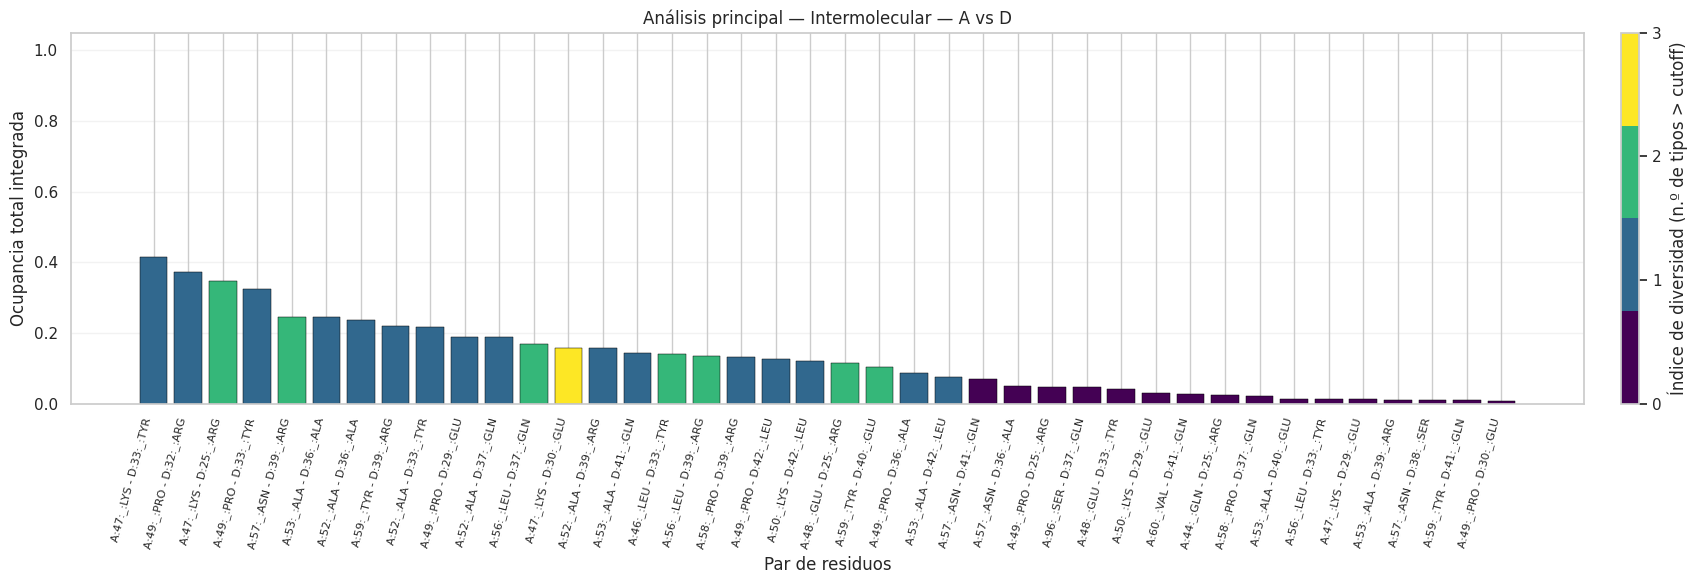

In [10]:
def graficar_ocupancia_diversidad(df, titulo, archivo):
    if df.empty:
        print(f"Sin datos para graficar: {titulo}")
        return

    datos_plot = top_candidatos(df, CONFIG["max_pairs_plot"]).copy()
    datos_plot["pair_short"] = datos_plot["pair"].astype(str)
    n_tipos = max(1, datos_plot["diversity"].max())

    fig, ax = plt.subplots(figsize=(max(10, 0.48 * len(datos_plot)), 6))
    cmap = plt.get_cmap("viridis", n_tipos + 1)
    norm = plt.Normalize(vmin=0, vmax=n_tipos)
    colores = cmap(norm(datos_plot["diversity"].to_numpy()))

    ax.bar(
        np.arange(len(datos_plot)),
        datos_plot["occupancy_total"],
        color=colores,
        edgecolor="black",
        linewidth=0.35
    )
    ax.set_xticks(np.arange(len(datos_plot)))
    ax.set_xticklabels(datos_plot["pair_short"], rotation=75, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Ocupancia total integrada")
    ax.set_xlabel("Par de residuos")
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.25)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=range(n_tipos + 1))
    cbar.set_label("Índice de diversidad (n.º de tipos > cutoff)")

    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / archivo, dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    plt.show()
    plt.close(fig)

graficar_ocupancia_diversidad(
    df_analisis,
    f"Análisis principal — {descripcion_analisis}",
    "11_principal_ocupancia_vs_diversidad.png"
)

## 10. Análisis obligatorio del blanco frente a péptidos

Este módulo se ejecuta **independientemente del filtro principal** y siempre considera los tres tipos (VDW, HBOND y SALTBRIDGE). Se restringe a contactos intermoleculares entre la cadena blanco y las cadenas péptido seleccionadas en la etapa de identificación biológica.

Se generan:
- Tabla completa por par de residuos;
- Resumen por tipo de interacción;
- Resumen por cadena péptido;
- Ranking de residuos del blanco;
- Ocupancia desglosada por residuo, pareja y tipo;
- Dinámica de contactos por frame;
- Gráfico de ocupancia integrada vs. diversidad.

**Importancia:** ofrece una caracterización consistente del blanco y de sus contactos con péptidos aunque el análisis principal haya sido intramolecular o se haya enfocado en otras cadenas.

In [11]:
TIPOS_BLANCO = TIPOS.copy()
contactos_blanco = {}
contactos_blanco_anotados = {}

for tipo in TIPOS_BLANCO:
    temp = CONTACTOS_ANOTADOS[tipo].copy()
    mask = (
        (temp["chain_1"] == BLANCO_CADENA) & temp["chain_2"].isin(CADENAS_PEPTIDOS)
    ) | (
        (temp["chain_2"] == BLANCO_CADENA) & temp["chain_1"].isin(CADENAS_PEPTIDOS)
    )
    temp = temp.loc[mask].drop_duplicates(["frame", "pair"]).copy()
    contactos_blanco[tipo] = temp[["frame", "pair"]].copy()
    contactos_blanco_anotados[tipo] = temp

df_blanco = tabla_metricas(contactos_blanco, TIPOS_BLANCO, N_FRAMES, CUTOFF)

def etiquetas_del_par(par):
    return [x.strip() for x in str(par).split(" - ", 1)]

def residuo_blanco_del_par(par):
    for etiqueta in etiquetas_del_par(par):
        info = mapa_residuos.get(etiqueta)
        if info and info["chain"] == BLANCO_CADENA:
            return etiqueta
    return None

def residuo_peptido_del_par(par):
    for etiqueta in etiquetas_del_par(par):
        info = mapa_residuos.get(etiqueta)
        if info and info["chain"] in CADENAS_PEPTIDOS:
            return etiqueta
    return None

def cadena_peptido_del_par(par):
    etiqueta = residuo_peptido_del_par(par)
    info = mapa_residuos.get(etiqueta) if etiqueta else None
    return info["chain"] if info else None

df_blanco["residuo_blanco"] = df_blanco["pair"].apply(residuo_blanco_del_par)
df_blanco["residuo_peptido"] = df_blanco["pair"].apply(residuo_peptido_del_par)
df_blanco["cadena_peptido"] = df_blanco["pair"].apply(cadena_peptido_del_par)

df_blanco_top20 = top_candidatos(df_blanco, CONFIG["top_n"])

print("=" * 78)
print(f"ANÁLISIS DEL BLANCO {BLANCO_CADENA} — {descripcion_cadenas[BLANCO_CADENA]}")
print("Cadenas péptido:", CADENAS_PEPTIDOS)
print(f"Frames: {N_FRAMES} | Pares únicos: {len(df_blanco)} | Cutoff: {CUTOFF:.1%}")
print("=" * 78)

print("\nTABLA COMPLETA DEL BLANCO")
display(df_blanco)
print("\nTOP 20 DE PARES BLANCO–PÉPTIDO")
display(df_blanco_top20)
imprimir_resumen(df_blanco, "Resumen integrado del blanco")

ANÁLISIS DEL BLANCO A — OSCP
Cadenas péptido: ['B', 'C', 'D']
Frames: 501 | Pares únicos: 192 | Cutoff: 5.0%

TABLA COMPLETA DEL BLANCO


,pair,vdw_occupancy,hbond_occupancy,saltbridge_occupancy,occupancy_total,diversity,diversity_normalized,main_interaction,residuo_blanco,residuo_peptido,cadena_peptido
0,A:65:_:LYS - C:41:_:GLN,0.185629,0.524950,0.0,0.602794,2,0.666667,HBOND,A:65:_:LYS,C:41:_:GLN,C
1,A:47:_:LYS - D:33:_:TYR,0.409182,0.009980,0.0,0.415170,1,0.333333,VDW,A:47:_:LYS,D:33:_:TYR,D
2,A:49:_:PRO - D:32:_:ARG,0.373253,0.000000,0.0,0.373253,1,0.333333,VDW,A:49:_:PRO,D:32:_:ARG,D
3,A:62:_:ARG - C:42:_:LEU,0.365269,0.000000,0.0,0.365269,1,0.333333,VDW,A:62:_:ARG,C:42:_:LEU,C
4,A:47:_:LYS - D:25:_:ARG,0.131737,0.327345,0.0,0.347305,2,0.666667,HBOND,A:47:_:LYS,D:25:_:ARG,D
...,...,...,...,...,...,...,...,...,...,...,...
187,A:94:_:ARG - C:35:_:ARG,0.001996,0.000000,0.0,0.001996,0,0.000000,VDW,A:94:_:ARG,C:35:_:ARG,C
188,A:94:_:ARG - C:38:_:SER,0.001996,0.000000,0.0,0.001996,0,0.000000,VDW,A:94:_:ARG,C:38:_:SER,C
189,A:95:_:LEU - C:40:_:GLU,0.001996,0.000000,0.0,0.001996,0,0.000000,VDW,A:95:_:LEU,C:40:_:GLU,C
190,A:97:_:ASN - C:41:_:GLN,0.000000,0.001996,0.0,0.001996,0,0.000000,HBOND,A:97:_:ASN,C:41:_:GLN,C



TOP 20 DE PARES BLANCO–PÉPTIDO


,pair,vdw_occupancy,hbond_occupancy,saltbridge_occupancy,occupancy_total,diversity,diversity_normalized,main_interaction,residuo_blanco,residuo_peptido,cadena_peptido
0,A:65:_:LYS - C:41:_:GLN,0.185629,0.524950,0.000000,0.602794,2,0.666667,HBOND,A:65:_:LYS,C:41:_:GLN,C
1,A:47:_:LYS - D:33:_:TYR,0.409182,0.009980,0.000000,0.415170,1,0.333333,VDW,A:47:_:LYS,D:33:_:TYR,D
2,A:49:_:PRO - D:32:_:ARG,0.373253,0.000000,0.000000,0.373253,1,0.333333,VDW,A:49:_:PRO,D:32:_:ARG,D
3,A:62:_:ARG - C:42:_:LEU,0.365269,0.000000,0.000000,0.365269,1,0.333333,VDW,A:62:_:ARG,C:42:_:LEU,C
4,A:47:_:LYS - D:25:_:ARG,0.131737,0.327345,0.000000,0.347305,2,0.666667,HBOND,A:47:_:LYS,D:25:_:ARG,D
5,A:49:_:PRO - D:33:_:TYR,0.325349,0.000000,0.000000,0.325349,1,0.333333,VDW,A:49:_:PRO,D:33:_:TYR,D
6,A:62:_:ARG - C:40:_:GLU,0.065868,0.251497,0.021956,0.261477,2,0.666667,HBOND,A:62:_:ARG,C:40:_:GLU,C
7,A:58:_:PRO - C:41:_:GLN,0.241517,0.055888,0.000000,0.259481,2,0.666667,VDW,A:58:_:PRO,C:41:_:GLN,C
8,A:57:_:ASN - D:39:_:ARG,0.209581,0.057884,0.000000,0.245509,2,0.666667,VDW,A:57:_:ASN,D:39:_:ARG,D
9,A:53:_:ALA - D:36:_:ALA,0.245509,0.000000,0.000000,0.245509,1,0.333333,VDW,A:53:_:ALA,D:36:_:ALA,D



Resumen integrado del blanco
Pares únicos: 192
Ocupancia integrada máxima: 60.3%
Diversidad máxima: 3
Tipo predominante más frecuente:


,cantidad
tipo,
VDW,118
HBOND,52
HBOND/SALTBRIDGE,12
VDW/HBOND,8
VDW/HBOND/SALTBRIDGE,2


## 10.1 Resúmenes de importancia biológica y dinámica temporal del blanco

Los resúmenes permiten pasar del par individual a una visión global: qué tipo aparece con mayor frecuencia, qué cadena péptido aporta más contactos y qué residuos del blanco concentran contactos persistentes. La tabla por frame muestra si la cantidad de contactos se mantiene o fluctúa a lo largo de la trayectoria.

**Importancia:** ayuda a priorizar residuos y regiones para una inspección estructural posterior. Estos indicadores son descriptivos y no reemplazan análisis energéticos o validación experimental.

In [12]:
# Resumen por tipo de interacción
filas_tipo = []
for tipo in TIPOS_BLANCO:
    col = COL_OCC[tipo]
    valores = df_blanco[col] if not df_blanco.empty else pd.Series(dtype=float)
    filas_tipo.append({
        "tipo_interaccion": tipo,
        "significado": SIGNIFICADO_INTERACCIONES[tipo],
        "pares_detectados": int((valores > 0).sum()),
        "pares_sobre_cutoff": int((valores > CUTOFF).sum()),
        "ocupancia_media_pares_detectados": float(valores[valores > 0].mean()) if (valores > 0).any() else 0.0,
        "ocupancia_maxima": float(valores.max()) if len(valores) else 0.0
    })
resumen_tipos_blanco = pd.DataFrame(filas_tipo)

# Resumen por cadena péptido
if not df_blanco.empty:
    resumen_cadenas_blanco = df_blanco.groupby("cadena_peptido", dropna=False).agg(
        pares_unicos=("pair", "nunique"),
        ocupancia_media=("occupancy_total", "mean"),
        ocupancia_maxima=("occupancy_total", "max"),
        diversidad_media=("diversity", "mean"),
        pares_persistentes=("occupancy_total", lambda s: int((s > CUTOFF).sum()))
    ).reset_index().sort_values(
        ["pares_unicos", "ocupancia_maxima"], ascending=False
    )
else:
    resumen_cadenas_blanco = pd.DataFrame(columns=[
        "cadena_peptido", "pares_unicos", "ocupancia_media",
        "ocupancia_maxima", "diversidad_media", "pares_persistentes"
    ])

# Ranking por residuo del blanco
if not df_blanco.empty:
    ranking_blanco = df_blanco.groupby("residuo_blanco", dropna=True).agg(
        pares_unicos=("pair", "nunique"),
        cadenas_peptido=("cadena_peptido", "nunique"),
        ocupancia_media=("occupancy_total", "mean"),
        ocupancia_maxima=("occupancy_total", "max"),
        diversidad_media=("diversity", "mean"),
        vdw_maxima=("vdw_occupancy", "max"),
        hbond_maxima=("hbond_occupancy", "max"),
        saltbridge_maxima=("saltbridge_occupancy", "max")
    ).reset_index().sort_values(
        ["ocupancia_maxima", "pares_unicos"], ascending=False
    )
else:
    ranking_blanco = pd.DataFrame(columns=[
        "residuo_blanco", "pares_unicos", "cadenas_peptido",
        "ocupancia_media", "ocupancia_maxima", "diversidad_media",
        "vdw_maxima", "hbond_maxima", "saltbridge_maxima"
    ])

# Ocupancia específica por residuo blanco–residuo péptido–tipo
registros = []
for tipo in TIPOS_BLANCO:
    temp = contactos_blanco_anotados[tipo].copy()
    if temp.empty:
        continue
    temp["residuo_blanco"] = temp["pair"].apply(residuo_blanco_del_par)
    temp["residuo_peptido"] = temp["pair"].apply(residuo_peptido_del_par)
    temp["cadena_peptido"] = temp["pair"].apply(cadena_peptido_del_par)
    agrupado = temp.groupby(
        ["residuo_blanco", "residuo_peptido", "cadena_peptido"]
    )["frame"].nunique() / N_FRAMES
    for clave, ocupancia in agrupado.items():
        registros.append({
            "tipo_interaccion": tipo,
            "residuo_blanco": clave[0],
            "residuo_peptido": clave[1],
            "cadena_peptido": clave[2],
            "ocupancia": float(ocupancia)
        })
df_residuo_tipo_blanco = pd.DataFrame(registros, columns=[
    "tipo_interaccion", "residuo_blanco", "residuo_peptido",
    "cadena_peptido", "ocupancia"
]).sort_values("ocupancia", ascending=False)

# Número de pares por frame, por tipo y total integrado
frames_resumen = pd.DataFrame({"frame": range(1, N_FRAMES + 1)})
for tipo in TIPOS_BLANCO:
    temp = contactos_blanco[tipo]
    conteo = temp.groupby("frame")["pair"].nunique().rename(f"pares_{tipo.lower()}")
    frames_resumen = frames_resumen.merge(
        conteo, left_on="frame", right_index=True, how="left"
    )
cols_frame = [f"pares_{t.lower()}" for t in TIPOS_BLANCO]
frames_resumen[cols_frame] = frames_resumen[cols_frame].fillna(0).astype(int)

union_blanco_frames = pd.concat(
    [contactos_blanco[t] for t in TIPOS_BLANCO], ignore_index=True
).drop_duplicates(["frame", "pair"])
total_frame = union_blanco_frames.groupby("frame")["pair"].nunique()
frames_resumen["pares_unicos_total"] = total_frame.reindex(
    frames_resumen["frame"], fill_value=0
).to_numpy()

print("TABLA — RESUMEN POR TIPO")
display(resumen_tipos_blanco)
print("TABLA — RESUMEN POR CADENA PÉPTIDO")
display(resumen_cadenas_blanco)
print("TABLA — RANKING DE RESIDUOS DEL BLANCO")
display(ranking_blanco)
print("TABLA — OCUPANCIA POR RESIDUO, PAREJA Y TIPO")
display(df_residuo_tipo_blanco)
print("TABLA — DINÁMICA DE CONTACTOS POR FRAME")
display(frames_resumen)

TABLA — RESUMEN POR TIPO


,tipo_interaccion,significado,pares_detectados,pares_sobre_cutoff,ocupancia_media_pares_detectados,ocupancia_maxima
0,VDW,Van der Waals: contactos de proximidad y compl...,174,46,0.047721,0.409182
1,HBOND,Puentes de hidrógeno: interacciones entre grup...,99,23,0.039840,0.524950
2,SALTBRIDGE,Interacciones iónicas/puentes salinos: contact...,25,5,0.029860,0.151697


TABLA — RESUMEN POR CADENA PÉPTIDO


,cadena_peptido,pares_unicos,ocupancia_media,ocupancia_maxima,diversidad_media,pares_persistentes
1,C,74,0.053649,0.602794,0.337838,17
0,B,62,0.027590,0.195609,0.258065,12
2,D,56,0.092066,0.415170,0.589286,25


TABLA — RANKING DE RESIDUOS DEL BLANCO


,residuo_blanco,pares_unicos,cadenas_peptido,ocupancia_media,ocupancia_maxima,diversidad_media,vdw_maxima,hbond_maxima,saltbridge_maxima
21,A:65:_:LYS,4,2,0.220559,0.602794,1.250000,0.185629,0.524950,0.099800
6,A:47:_:LYS,7,2,0.150271,0.415170,1.285714,0.409182,0.327345,0.151697
8,A:49:_:PRO,7,1,0.165098,0.373253,0.714286,0.373253,0.000000,0.000000
18,A:62:_:ARG,14,2,0.060308,0.365269,0.285714,0.365269,0.251497,0.021956
14,A:58:_:PRO,14,3,0.064585,0.259481,0.428571,0.241517,0.085828,0.000000
11,A:53:_:ALA,8,2,0.062625,0.245509,0.375000,0.245509,0.133733,0.000000
13,A:57:_:ASN,8,3,0.051647,0.245509,0.250000,0.209581,0.057884,0.000000
10,A:52:_:ALA,4,1,0.200100,0.237525,1.000000,0.237525,0.155689,0.000000
29,A:93:_:GLY,6,2,0.069528,0.235529,0.333333,0.231537,0.015968,0.000000
15,A:59:_:TYR,25,3,0.052774,0.219561,0.480000,0.219561,0.191617,0.000000


TABLA — OCUPANCIA POR RESIDUO, PAREJA Y TIPO


,tipo_interaccion,residuo_blanco,residuo_peptido,cadena_peptido,ocupancia
241,HBOND,A:65:_:LYS,C:41:_:GLN,C,0.524950
12,VDW,A:47:_:LYS,D:33:_:TYR,D,0.409182
20,VDW,A:49:_:PRO,D:32:_:ARG,D,0.373253
115,VDW,A:62:_:ARG,C:42:_:LEU,C,0.365269
183,HBOND,A:47:_:LYS,D:25:_:ARG,D,0.327345
...,...,...,...,...,...
1,VDW,A:103:_:SER,C:25:_:ARG,C,0.001996
294,SALTBRIDGE,A:91:_:GLU,B:25:_:ARG,B,0.001996
295,SALTBRIDGE,A:91:_:GLU,C:39:_:ARG,C,0.001996
296,SALTBRIDGE,A:94:_:ARG,B:31:_:GLU,B,0.001996


TABLA — DINÁMICA DE CONTACTOS POR FRAME


,frame,pares_vdw,pares_hbond,pares_saltbridge,pares_unicos_total
0,1,7,3,1,10
1,2,7,2,1,9
2,3,7,1,0,8
3,4,11,2,0,12
4,5,7,2,1,7
...,...,...,...,...,...
496,497,11,5,1,14
497,498,10,5,1,12
498,499,12,4,1,16
499,500,6,6,1,12


## 10.2 Figuras complementarias del blanco

Se generan heatmaps de ocupancia por tipo y total, un ranking visual de residuos del blanco y una curva temporal del número de pares por frame. También se produce el gráfico de barras de ocupancia integrada coloreado por diversidad.

**Importancia:** estas figuras permiten identificar patrones persistentes y fluctuaciones que podrían quedar ocultos en una tabla extensa.

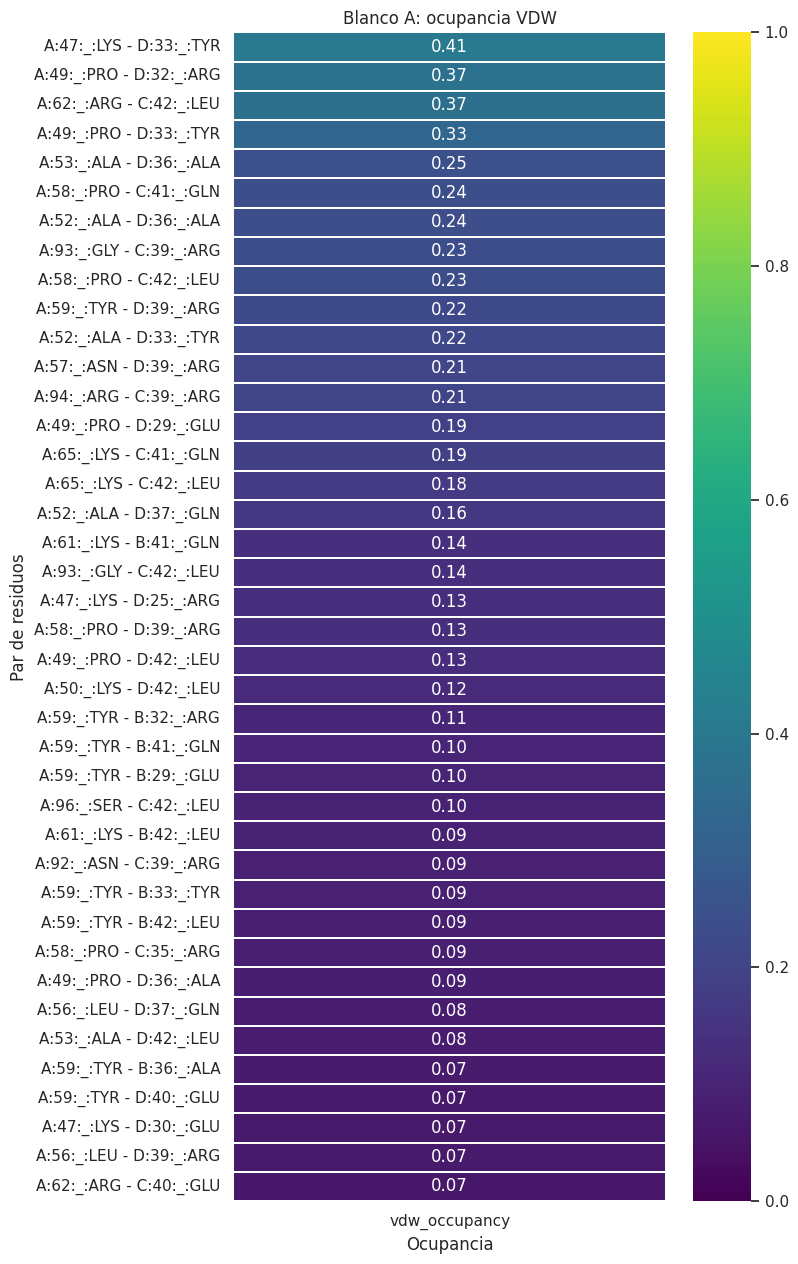

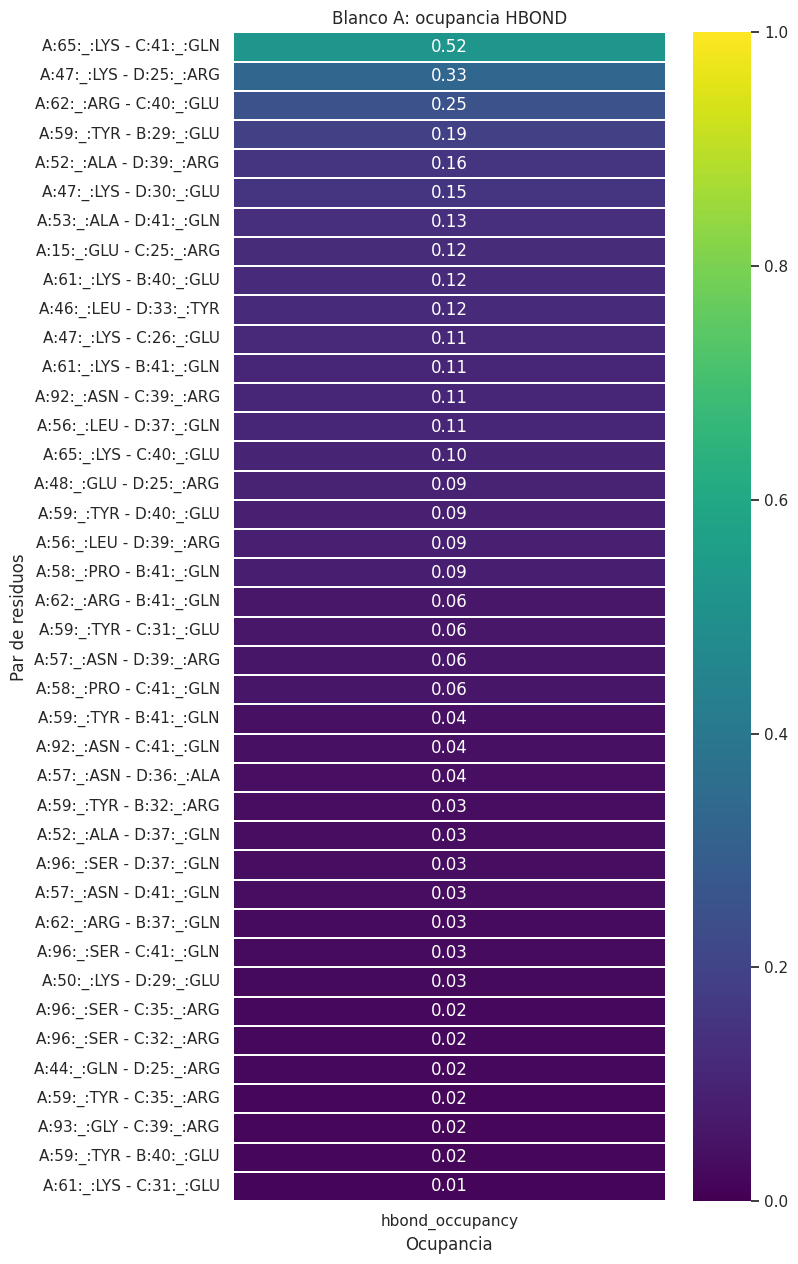

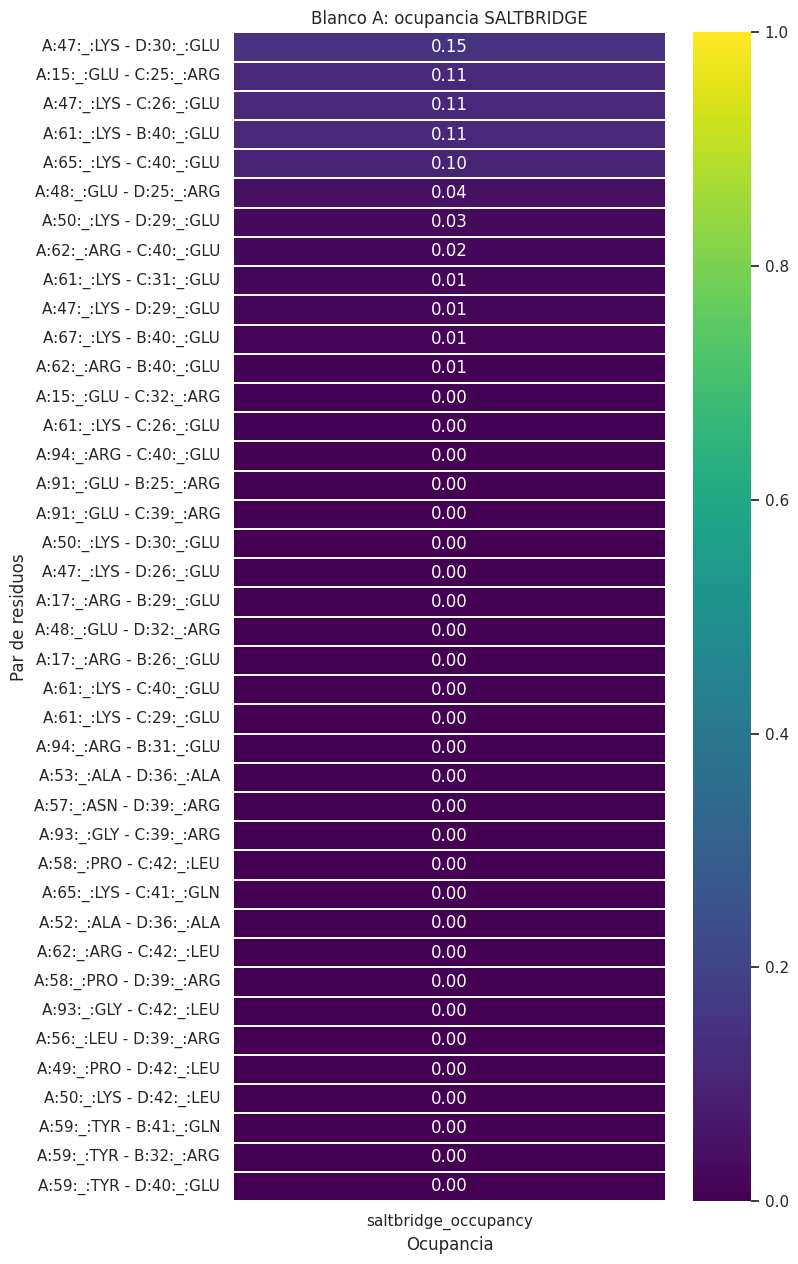

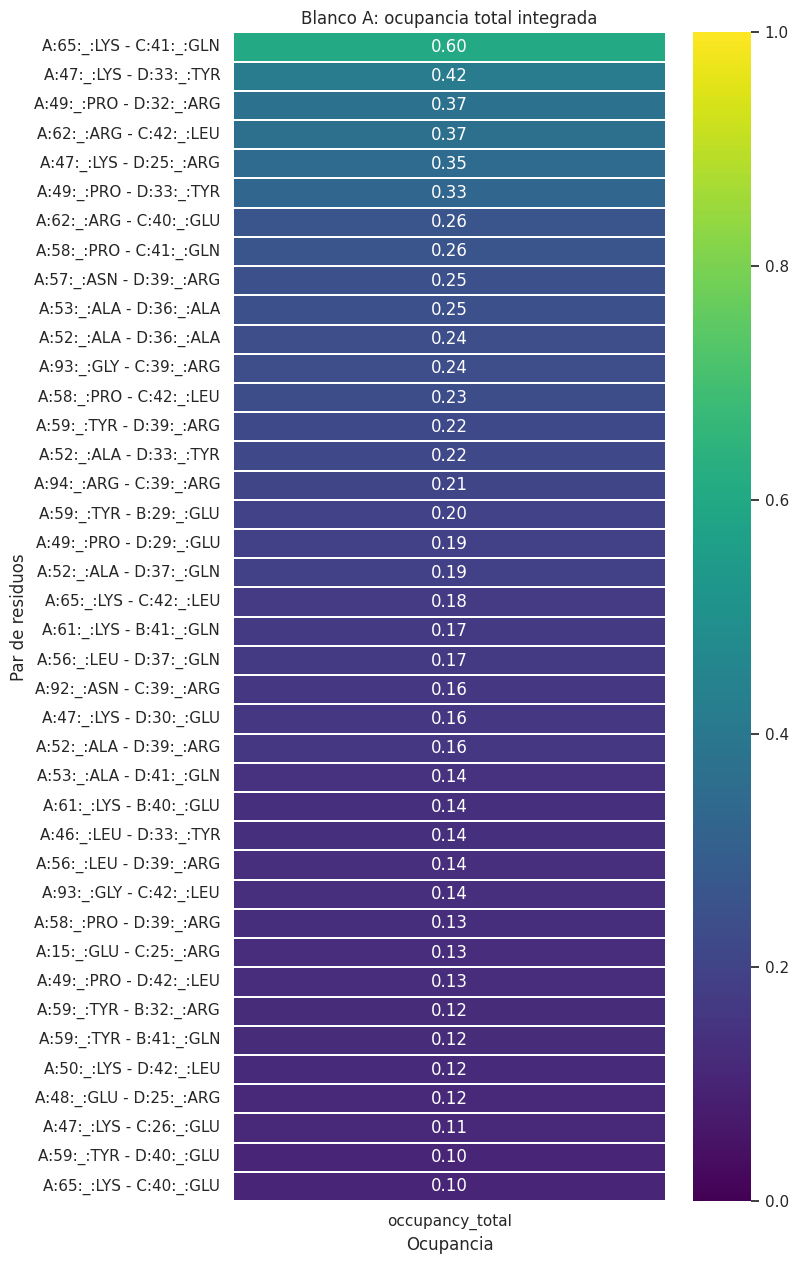

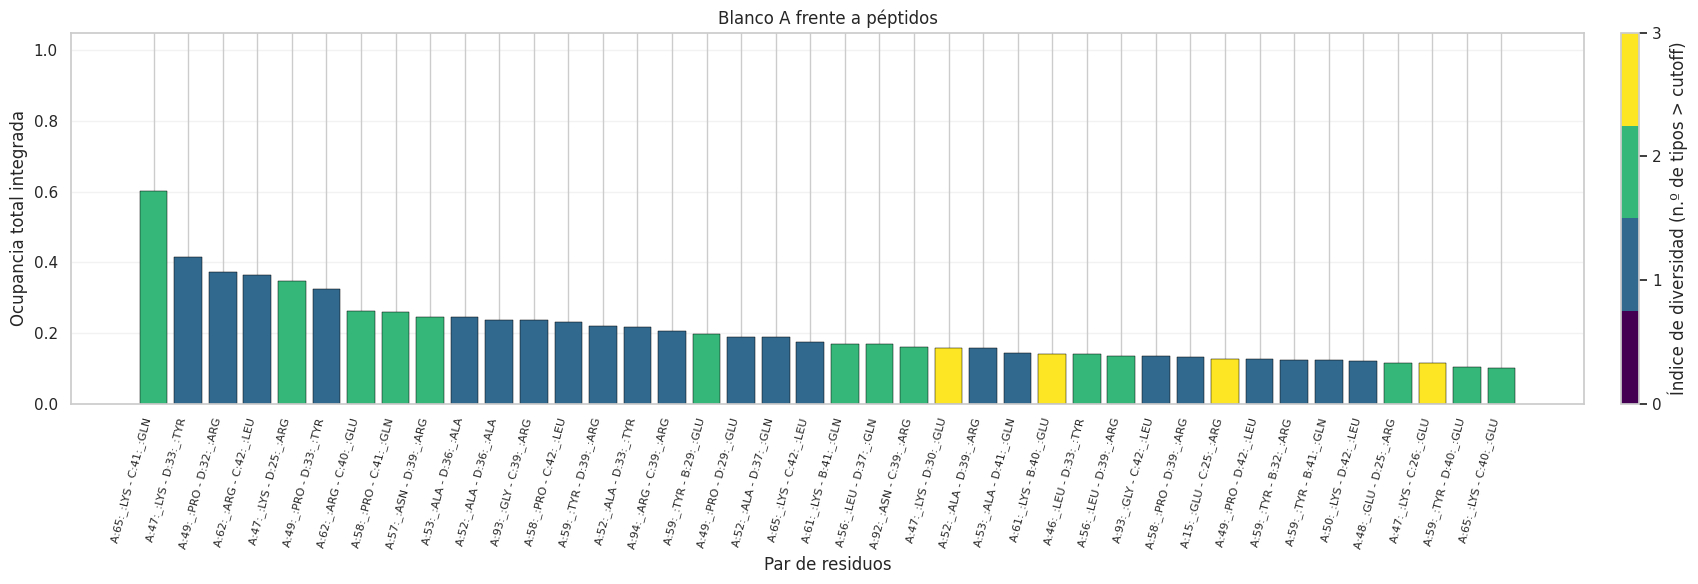

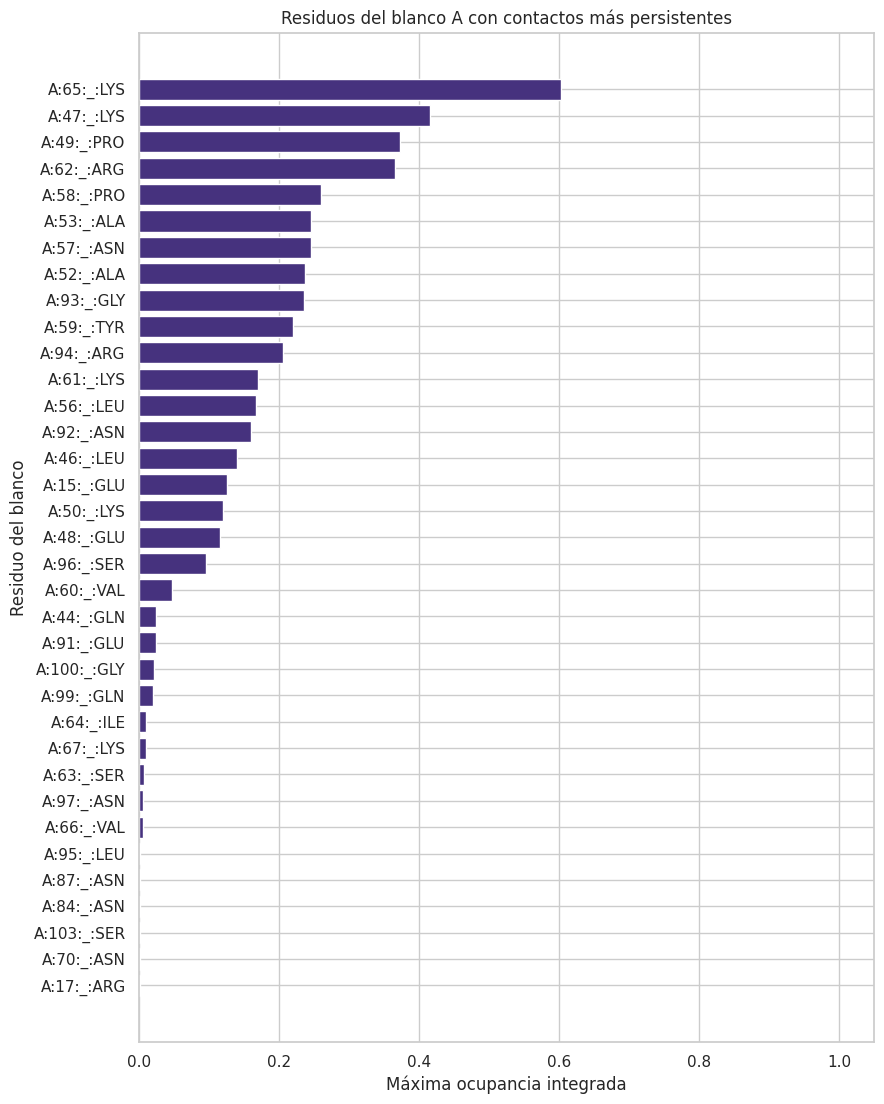

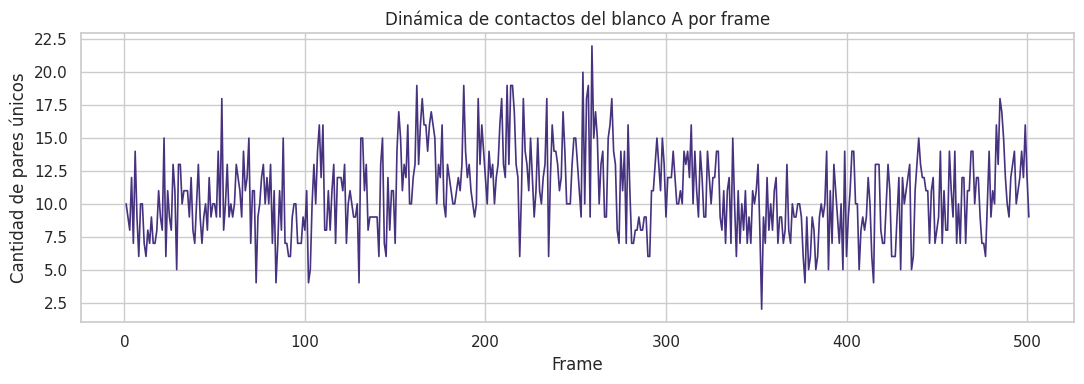

In [13]:
def graficar_heatmap(df, columna, titulo, archivo):
    if df.empty:
        print(f"Sin datos para generar {titulo}")
        return
    datos_plot = df.sort_values(columna, ascending=False).head(
        CONFIG["max_pairs_plot"]
    ).set_index("pair")[[columna]]
    fig, ax = plt.subplots(figsize=(8, max(4, min(14, 0.32 * len(datos_plot)))))
    sns.heatmap(
        datos_plot, annot=True, fmt=".2f", vmin=0, vmax=1,
        cmap="viridis", linewidths=0.25, ax=ax
    )
    ax.set_title(titulo)
    ax.set_xlabel("Ocupancia")
    ax.set_ylabel("Par de residuos")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / archivo, dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    plt.show()
    plt.close(fig)

for tipo in TIPOS_BLANCO:
    graficar_heatmap(
        df_blanco, COL_OCC[tipo],
        f"Blanco {BLANCO_CADENA}: ocupancia {tipo}",
        f"12_blanco_heatmap_{tipo.lower()}.png"
    )
graficar_heatmap(
    df_blanco, "occupancy_total",
    f"Blanco {BLANCO_CADENA}: ocupancia total integrada",
    "13_blanco_heatmap_ocupancia_total.png"
)

graficar_ocupancia_diversidad(
    df_blanco,
    f"Blanco {BLANCO_CADENA} frente a péptidos",
    "14_blanco_ocupancia_vs_diversidad.png"
)

if not ranking_blanco.empty:
    top_res = ranking_blanco.head(CONFIG["max_pairs_plot"]).sort_values(
        "ocupancia_maxima", ascending=True
    )
    fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(top_res))))
    ax.barh(top_res["residuo_blanco"], top_res["ocupancia_maxima"])
    ax.set_title(f"Residuos del blanco {BLANCO_CADENA} con contactos más persistentes")
    ax.set_xlabel("Máxima ocupancia integrada")
    ax.set_ylabel("Residuo del blanco")
    ax.set_xlim(0, 1.05)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "15_blanco_ranking_residuos.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(frames_resumen["frame"], frames_resumen["pares_unicos_total"], linewidth=1.2)
ax.set_title(f"Dinámica de contactos del blanco {BLANCO_CADENA} por frame")
ax.set_xlabel("Frame")
ax.set_ylabel("Cantidad de pares únicos")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "16_blanco_dinamica_por_frame.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
plt.close(fig)

## 11. Descripción – Resumen global de residuos del blanco y hotspots

Este código realiza un análisis general de los residuos de la proteína blanco para determinar cuántos cumplen el criterio de hotspot (ocupancia integrada máxima ≥ 50 %), cual es el péptido con mas interacciones y cuál es el péptido más específico.

**Importancia:** facilita la lectura inicial de los resultados, pero no debe interpretarse como prueba de afinidad, mecanismo o relevancia biológica.


IDENTIFICACIÓN DE RESIDUOS HOTSPOT
Umbral de ocupancia: 50.0%
Cantidad de hotspots identificados: 1
Residuos hotspot:
 - A:65:_:LYS

RANKING DE PÉPTIDOS SEGÚN INTERACCIÓN CON HOTSPOTS


,cadena_peptido,descripcion_peptido,hotspots_contactados,total_hotspots,cobertura_hotspots,pares_con_hotspots,ocupancia_media_hotspots,ocupancia_maxima_hotspots,residuos_hotspot_contactados
0,C,IF1,1,1,1.0,3,0.293413,0.602794,A:65:_:LYS
1,B,IF1,0,1,0.0,0,0.000000,0.000000,
2,D,IF1,0,1,0.0,0,0.000000,0.000000,


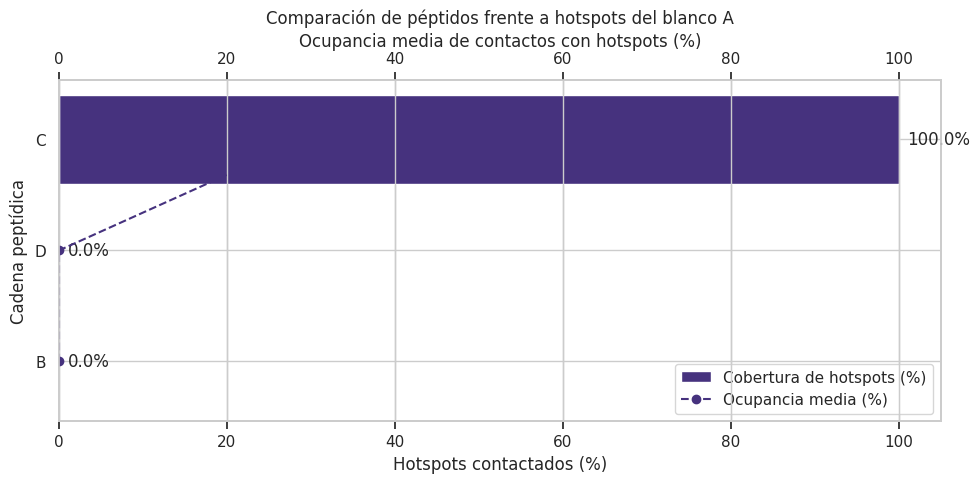


INTERPRETACIÓN AUTOMÁTICA ORIENTATIVA DEL BLANCO
El blanco A (OSCP) presentó 192 pares únicos con las cadenas péptido seleccionadas. El par más persistente fue A:65:_:LYS - C:41:_:GLN (ocupancia integrada 60.3%; diversidad 2). El tipo con más pares sobre el cutoff de 5.0% fue VDW (46 pares). El residuo del blanco con mayor ocupancia máxima fue A:65:_:LYS (60.3%). La cadena péptido con más pares detectados fue C (IF1). El péptido con mayor cobertura de hotspots fue la cadena C (IF1), que interactuó con 1 de 1 hotspots (100.0% de cobertura). La ocupancia media de sus contactos con hotspots fue 29.3%. La identificación de hotspots se basa en la ocupancia máxima de contactos (umbral >= 50.0%). La comparación de péptidos prioriza la cobertura de esos residuos y luego la ocupancia media. Estos indicadores describen contactos persistentes, pero no demuestran por sí solos afinidad, especificidad energética ni relevancia funcional.


In [15]:
# ============================================================
# INTERPRETACIÓN AUTOMÁTICA ORIENTATIVA DEL BLANCO
# + IDENTIFICACIÓN DEL PÉPTIDO CON MAYOR COBERTURA DE HOTSPOTS
# ============================================================

# Umbral para definir un residuo hotspot:
# se considera hotspot si su ocupancia máxima es >= 50 %.
CUTOFF_HOTSPOT = 0.50

if df_blanco.empty:

    resultado_preliminar = (
        f"No se detectaron contactos intermoleculares mapeados entre "
        f"el blanco {BLANCO_CADENA} y las cadenas péptido seleccionadas "
        f"{CADENAS_PEPTIDOS}. Revisar la selección de cadenas, el mapeo "
        "PDB-RING y el contenido de las matrices."
    )

    resumen_especificidad_peptidos = pd.DataFrame()
    hotspots_blanco = []

else:

    # --------------------------------------------------------
    # 1. INTERPRETACIÓN GENERAL DEL BLANCO
    # --------------------------------------------------------

    top_par = df_blanco.sort_values(
        "occupancy_total", ascending=False
    ).iloc[0]

    top_tipo = resumen_tipos_blanco.sort_values(
        ["pares_sobre_cutoff", "ocupancia_maxima"],
        ascending=False
    ).iloc[0]

    resultado_preliminar = (
        f"El blanco {BLANCO_CADENA} "
        f"({descripcion_cadenas[BLANCO_CADENA]}) presentó "
        f"{len(df_blanco)} pares únicos con las cadenas péptido "
        f"seleccionadas. El par más persistente fue "
        f"{top_par['pair']} (ocupancia integrada "
        f"{top_par['occupancy_total']:.1%}; diversidad "
        f"{int(top_par['diversity'])}). "
        f"El tipo con más pares sobre el cutoff de {CUTOFF:.1%} "
        f"fue {top_tipo['tipo_interaccion']} "
        f"({int(top_tipo['pares_sobre_cutoff'])} pares)."
    )

    if not ranking_blanco.empty:
        r = ranking_blanco.iloc[0]
        resultado_preliminar += (
            f" El residuo del blanco con mayor ocupancia máxima fue "
            f"{r['residuo_blanco']} ({r['ocupancia_maxima']:.1%})."
        )

    if not resumen_cadenas_blanco.empty:
        c = resumen_cadenas_blanco.iloc[0]["cadena_peptido"]
        resultado_preliminar += (
            f" La cadena péptido con más pares detectados fue {c} "
            f"({descripcion_cadenas.get(c, 'sin descripción')})."
        )

    # --------------------------------------------------------
    # 2. IDENTIFICACIÓN DE RESIDUOS HOTSPOT DEL BLANCO
    # --------------------------------------------------------

    hotspots_blanco = ranking_blanco.loc[
        ranking_blanco["ocupancia_maxima"] >= CUTOFF_HOTSPOT,
        "residuo_blanco"
    ].dropna().unique().tolist()

    print("\n" + "=" * 75)
    print("IDENTIFICACIÓN DE RESIDUOS HOTSPOT")
    print("=" * 75)

    print(f"Umbral de ocupancia: {CUTOFF_HOTSPOT:.1%}")
    print(f"Cantidad de hotspots identificados: {len(hotspots_blanco)}")

    if hotspots_blanco:
        print("Residuos hotspot:")
        for residuo in hotspots_blanco:
            print(" -", residuo)
    else:
        print("No se identificaron residuos que superen el umbral establecido.")

    # --------------------------------------------------------
    # 3. EVALUACIÓN DE CADA PÉPTIDO FRENTE A LOS HOTSPOTS
    # --------------------------------------------------------

    columnas_resumen = [
        "cadena_peptido",
        "descripcion_peptido",
        "hotspots_contactados",
        "total_hotspots",
        "cobertura_hotspots",
        "pares_con_hotspots",
        "ocupancia_media_hotspots",
        "ocupancia_maxima_hotspots"
    ]

    filas_especificidad = []

    for cadena in CADENAS_PEPTIDOS:

        # Contactos de la cadena con los residuos hotspot.
        contactos_hotspots = df_blanco[
            (df_blanco["cadena_peptido"] == cadena) &
            (df_blanco["residuo_blanco"].isin(hotspots_blanco)) &
            (df_blanco["occupancy_total"] > CUTOFF)
        ].copy()

        # Cantidad de hotspots diferentes contactados.
        hotspots_contactados = (
            contactos_hotspots["residuo_blanco"].nunique()
        )

        # Cobertura de hotspots del blanco.
        cobertura = (
            hotspots_contactados / len(hotspots_blanco)
            if hotspots_blanco else 0
        )

        # Ocupancias de los contactos con hotspots.
        ocupancia_media = (
            contactos_hotspots["occupancy_total"].mean()
            if not contactos_hotspots.empty else 0
        )

        ocupancia_maxima = (
            contactos_hotspots["occupancy_total"].max()
            if not contactos_hotspots.empty else 0
        )

        filas_especificidad.append({
            "cadena_peptido": cadena,
            "descripcion_peptido": descripcion_cadenas.get(
                cadena, "Sin descripción"
            ),
            "hotspots_contactados": hotspots_contactados,
            "total_hotspots": len(hotspots_blanco),
            "cobertura_hotspots": cobertura,
            "pares_con_hotspots": len(contactos_hotspots),
            "ocupancia_media_hotspots": ocupancia_media,
            "ocupancia_maxima_hotspots": ocupancia_maxima,
            "residuos_hotspot_contactados": ", ".join(
                sorted(
                    contactos_hotspots["residuo_blanco"].dropna().unique()
                )
            )
        })

    resumen_especificidad_peptidos = pd.DataFrame(
        filas_especificidad
    )

    # --------------------------------------------------------
    # 4. RANKING DEL PÉPTIDO CON MAYOR INTERACCIÓN CON HOTSPOTS
    # --------------------------------------------------------

    resumen_especificidad_peptidos = (
        resumen_especificidad_peptidos.sort_values(
            [
                "cobertura_hotspots",
                "ocupancia_media_hotspots",
                "ocupancia_maxima_hotspots"
            ],
            ascending=False
        ).reset_index(drop=True)
    )

    print("\nRANKING DE PÉPTIDOS SEGÚN INTERACCIÓN CON HOTSPOTS")
    display(resumen_especificidad_peptidos)

    # Selección del candidato.
    if (
        not resumen_especificidad_peptidos.empty
        and len(hotspots_blanco) > 0
        and resumen_especificidad_peptidos.iloc[0]["hotspots_contactados"] > 0
    ):

        mejor_peptido = resumen_especificidad_peptidos.iloc[0]

        resultado_preliminar += (
            f" El péptido con mayor cobertura de hotspots fue la cadena "
            f"{mejor_peptido['cadena_peptido']} "
            f"({mejor_peptido['descripcion_peptido']}), que interactuó "
            f"con {int(mejor_peptido['hotspots_contactados'])} de "
            f"{int(mejor_peptido['total_hotspots'])} hotspots "
            f"({mejor_peptido['cobertura_hotspots']:.1%} de cobertura). "
            f"La ocupancia media de sus contactos con hotspots fue "
            f"{mejor_peptido['ocupancia_media_hotspots']:.1%}."
        )

    else:

        resultado_preliminar += (
            " No fue posible identificar un péptido con contactos "
            "persistentes con los hotspots del blanco según los "
            "umbrales establecidos."
        )

    # --------------------------------------------------------
    # 5. GRÁFICO COMPARATIVO DE PÉPTIDOS Y HOTSPOTS
    # --------------------------------------------------------

    if not resumen_especificidad_peptidos.empty:

        datos_grafico = resumen_especificidad_peptidos.sort_values(
            "cobertura_hotspots", ascending=True
        )

        fig, ax1 = plt.subplots(figsize=(10, 5))

        # Barras: porcentaje de hotspots contactados.
        barras = ax1.barh(
            datos_grafico["cadena_peptido"],
            datos_grafico["cobertura_hotspots"] * 100,
            label="Cobertura de hotspots (%)"
        )

        ax1.set_xlabel("Hotspots contactados (%)")
        ax1.set_ylabel("Cadena peptídica")
        ax1.set_xlim(0, 105)
        ax1.set_title(
            f"Comparación de péptidos frente a hotspots del blanco "
            f"{BLANCO_CADENA}"
        )

        # Etiquetas de cobertura.
        for barra, valor in zip(
            barras,
            datos_grafico["cobertura_hotspots"] * 100
        ):
            ax1.text(
                valor + 1,
                barra.get_y() + barra.get_height() / 2,
                f"{valor:.1f}%",
                va="center"
            )

        # Línea: ocupancia media de los contactos con hotspots.
        ax2 = ax1.twiny()

        ax2.plot(
            datos_grafico["ocupancia_media_hotspots"] * 100,
            datos_grafico["cadena_peptido"],
            marker="o",
            linestyle="--",
            label="Ocupancia media (%)"
        )

        ax2.set_xlabel("Ocupancia media de contactos con hotspots (%)")
        ax2.set_xlim(0, 105)

        # Leyenda conjunta.
        elementos1, etiquetas1 = ax1.get_legend_handles_labels()
        elementos2, etiquetas2 = ax2.get_legend_handles_labels()

        ax1.legend(
            elementos1 + elementos2,
            etiquetas1 + etiquetas2,
            loc="lower right"
        )

        fig.tight_layout()

        fig.savefig(
            OUTPUT_DIR / "17_comparacion_peptidos_hotspots.png",
            dpi=CONFIG["figure_dpi"],
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # --------------------------------------------------------
    # 6. GUARDAR TABLA DE ESPECIFICIDAD
    # --------------------------------------------------------

    resumen_especificidad_peptidos.to_csv(
        OUTPUT_DIR / "10_ranking_peptidos_hotspots.csv",
        index=False
    )

    # Advertencia metodológica.
    resultado_preliminar += (
        " La identificación de hotspots se basa en la ocupancia máxima "
        f"de contactos (umbral >= {CUTOFF_HOTSPOT:.1%}). La comparación "
        "de péptidos prioriza la cobertura de esos residuos y luego la "
        "ocupancia media. Estos indicadores describen contactos "
        "persistentes, pero no demuestran por sí solos afinidad, "
        "especificidad energética ni relevancia funcional."
    )


# ------------------------------------------------------------
# 7. MOSTRAR Y GUARDAR INTERPRETACIÓN FINAL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INTERPRETACIÓN AUTOMÁTICA ORIENTATIVA DEL BLANCO")
print("=" * 75)

print(resultado_preliminar)

with open(
    OUTPUT_DIR / "07_resultado_preliminar_blanco.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(resultado_preliminar + "\n")

## 12. Exportación de tablas, parámetros, figuras y descarga

Se guardan por separado los resultados del análisis principal y los del blanco, además de los resúmenes, el mapeo PDB–RING, los parámetros y una descripción de los archivos. Finalmente se crea un ZIP descargable.

**Importancia:** conserva la trazabilidad del análisis y permite reutilizar las tablas y figuras en informes o comparaciones entre simulaciones.

In [16]:
# Tablas del análisis principal
df_analisis.to_csv(OUTPUT_DIR / "01_analisis_principal_completo.csv", index=False)
df_principal_top20.to_csv(OUTPUT_DIR / "02_analisis_principal_top20.csv", index=False)

# Tablas del análisis obligatorio del blanco
df_blanco.to_csv(OUTPUT_DIR / "03_blanco_pares_completo.csv", index=False)
df_blanco_top20.to_csv(OUTPUT_DIR / "04_blanco_top20.csv", index=False)
resumen_tipos_blanco.to_csv(OUTPUT_DIR / "05_blanco_resumen_por_tipo.csv", index=False)
resumen_cadenas_blanco.to_csv(OUTPUT_DIR / "06_blanco_resumen_por_cadena_peptido.csv", index=False)
ranking_blanco.to_csv(OUTPUT_DIR / "07_blanco_ranking_residuos.csv", index=False)
df_residuo_tipo_blanco.to_csv(OUTPUT_DIR / "08_blanco_ocupancia_residuo_tipo.csv", index=False)
frames_resumen.to_csv(OUTPUT_DIR / "09_blanco_dinamica_por_frame.csv", index=False)
tabla_mapeo.to_csv(OUTPUT_DIR / "10_auditoria_mapeo_PDB_RING.csv", index=False)
resumen_cadenas_mapeo.to_csv(
    OUTPUT_DIR / "11_auditoria_residuos_por_cadena.csv", index=False
)
residuos_ausentes_ring.to_csv(
    OUTPUT_DIR / "12_advertencia_residuos_PDB_ausentes_en_RING.csv", index=False
)

parametros = {
    "modo_analisis_principal": modo_analisis,
    "descripcion_analisis_principal": descripcion_analisis,
    "cadenas_analisis_principal": CADENAS_ANALISIS,
    "tipos_analisis_principal": TIPOS_PRINCIPAL,
    "cadena_blanco": BLANCO_CADENA,
    "descripcion_blanco": descripcion_cadenas[BLANCO_CADENA],
    "cadenas_peptido": CADENAS_PEPTIDOS,
    "descripciones_cadenas": descripcion_cadenas,
    "n_frames": N_FRAMES,
    "n_etiquetas_RING": len(residues),
    "n_residuos_mapeados_PDB_RING": len(mapa_residuos),
    "residuos_presentes_en_PDB_ausentes_en_RING": [
        {
            "cadena": cadena,
            "numero": numero,
            "codigo_insercion": insercion,
            "nombre": nombre
        }
        for cadena, numero, insercion, nombre in residuos_pdb_sin_ring
    ],
    "cutoff_diversidad": CUTOFF,
    "definicion_ocupancia_total": (
        "Fracción de frames en los que aparece al menos uno de los tipos de "
        "interacción para un par; cada frame-par se cuenta una sola vez."
    ),
    "definicion_diversidad": (
        "Cantidad de tipos de interacción con ocupancia > cutoff."
    ),
    "advertencia": (
        "La ocupancia describe persistencia temporal y no equivale por sí sola "
        "a afinidad, energía libre o importancia funcional."
    )
}
with open(OUTPUT_DIR / "11_parametros_analisis.json", "w", encoding="utf-8") as f:
    json.dump(parametros, f, indent=2, ensure_ascii=False)

readme = OUTPUT_DIR / "README_resultados.txt"
with open(readme, "w", encoding="utf-8") as f:
    f.write("RESULTADOS DEL ANÁLISIS DE INTERACCIONES RING\n")
    f.write("=" * 48 + "\n\n")
    f.write(f"Análisis principal: {descripcion_analisis}\n")
    f.write(f"Tipos principales: {', '.join(TIPOS_PRINCIPAL)}\n")
    f.write(f"Blanco: {BLANCO_CADENA} — {descripcion_cadenas[BLANCO_CADENA]}\n")
    f.write(f"Cadenas péptido: {', '.join(CADENAS_PEPTIDOS)}\n")
    f.write(f"Frames: {N_FRAMES}; cutoff diversidad: {CUTOFF:.3f}\n\n")
    f.write("CONTENIDO\n")
    f.write("01-02: tabla completa y Top 20 del análisis principal.\n")
    f.write("03-04: tabla completa y Top 20 del análisis del blanco.\n")
    f.write("05: resumen de VDW, HBOND y SALTBRIDGE del blanco.\n")
    f.write("06: resumen por cadena péptido.\n")
    f.write("07: ranking de residuos del blanco.\n")
    f.write("08: ocupancia por residuo blanco, residuo péptido y tipo.\n")
    f.write("09: dinámica de contactos por frame.\n")
    f.write("10: auditoría de correspondencias PDB-RING.\n")
    f.write("11: parámetros y definiciones del análisis.\n\n")
    f.write("Las figuras PNG se guardan en esta misma carpeta.\n")
    f.write("La ocupancia no demuestra por sí sola afinidad ni energía libre.\n")

zip_path = shutil.make_archive(
    str(OUTPUT_DIR.resolve()), "zip",
    root_dir=str(OUTPUT_DIR.resolve())
)
print("✓ Resultados guardados en:", OUTPUT_DIR.resolve())
print("✓ Archivo ZIP creado:", zip_path)

if EN_COLAB:
    files.download(zip_path)
else:
    print("En Jupyter local, descargá el ZIP desde la carpeta de trabajo.")

✓ Resultados guardados en: /content/resultados_ring
✓ Archivo ZIP creado: /content/resultados_ring.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>